# 💬 Análise de Sentimento de Reviews de Produtos

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** classificação binária de textos (NLP)

> **Resumo:** construímos um modelo que lê reviews de clientes da Amazon Alexa e identifica automaticamente os **negativos**, para que o time de atendimento consiga agir rápido com os clientes insatisfeitos.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados
- **FASE 03:** Modelagem dos Dados
- **FASE 04:** Avaliação
- **FASE 05:** Implantação
- **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** estrutura CRISP-DM e correções de metodologia em relação à versão original (que foi mantida no repositório para mostrar a evolução): remoção de duplicadas antes da divisão treino/teste, pipeline sem vazamento, negações mantidas no texto, métricas focadas na classe negativa e limiar escolhido sem usar o teste. A v2 segue o **padrão de construção** dos projetos do autor: testes estatísticos nas hipóteses, divisão treino/validação/teste (60/20/20), uma seção por algoritmo (XGBoost, Random Forest, LightGBM, Regressão Logística e Naive Bayes), teste anti-vazamento e ficha do modelo. Executado com Python 3.13, pandas 3.0 e scikit-learn 1.9.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Empresas recebem diariamente centenas de avaliações de clientes em sites e redes sociais. Ler tudo manualmente é inviável, e um cliente insatisfeito sem resposta pode virar uma reclamação pública, uma devolução ou um cliente perdido.

Nesta base, temos **reviews reais de clientes dos produtos Amazon Alexa** (Echo, Echo Dot, Fire TV Stick etc.), com o texto escrito pelo cliente, a nota de 1 a 5 e a variação do produto.

**Fonte dos dados:** [Amazon Alexa Reviews – Kaggle](https://www.kaggle.com/sid321axn/amazon-alexa-reviews)

## 🎯 Objetivo

Construir um classificador que receba o **texto de um review** e indique se ele é **positivo ou negativo**, priorizando **encontrar os reviews negativos**.

> **Pergunta de negócio:** *É possível identificar automaticamente os clientes insatisfeitos a partir do que eles escrevem, para que o time de atendimento aja antes que o problema cresça?*

**Stakeholder:** time de Relacionamento com o Cliente / Relações Públicas.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | Review (uma linha = uma avaliação de um cliente) |
| **Tipo de problema** | Classificação binária supervisionada: **1 = review negativo**, 0 = review positivo |
| **Desafio principal** | Base **desbalanceada**: apenas ~8% dos reviews são negativos |
| **Métrica principal** | **Recall e F1 da classe negativa**: o importante é encontrar os clientes insatisfeitos, sem gerar alertas falsos demais |
| **Entrega** | Modelo salvo + app Streamlit que classifica um review e mostra as palavras que pesaram na decisão |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir o problema, a métrica e o formato da entrega |
| **02. Preparação dos dados** | Limpar (nulos, vazios e duplicados), explorar os textos (EDA) e criar variáveis |
| **03. Modelagem** | Transformar texto em números (TF-IDF), dividir em treino/validação/teste, comparar 5 algoritmos, ajustar hiperparâmetros, escolher o limiar, testar calibração e vazamento |
| **04. Avaliação** | Medir o modelo no teste, ler os acertos e erros e descobrir as palavras mais importantes |
| **05. Implantação** | Salvar o modelo e a ficha do modelo, simular reviews novos e medir o ganho contra um sorteio |

# FASE 02: PREPARAÇÃO DOS DADOS

Nesta fase vamos **conhecer e preparar a base**: carregar os dados, conferir a qualidade (nulos, textos vazios e duplicados), explorar os textos e criar as variáveis usadas no modelo.

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import time
import pickle

import numpy             as np
import pandas            as pd
import seaborn           as sns
import matplotlib.pyplot as plt

from scipy                           import stats
from scipy.stats                     import loguniform
from sklearn.base                    import clone
from sklearn.model_selection         import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose                 import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing           import OneHotEncoder
from sklearn.linear_model            import LogisticRegression
from sklearn.naive_bayes             import MultinomialNB
from sklearn.ensemble                import RandomForestClassifier
from sklearn.inspection              import permutation_importance
from sklearn.metrics                 import (classification_report, ConfusionMatrixDisplay, precision_recall_curve,
                                             precision_score, recall_score, f1_score, brier_score_loss)
from imblearn.pipeline               import Pipeline
from imblearn.over_sampling          import SMOTE
import xgboost                       as xgb
import lightgbm                      as lgb

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 150)
SEED = 42   # semente fixa: resultados reproduzíveis a cada execução

#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto:

| Arquivo | Função | Para que serve |
|---|---|---|
| `src/texto.py` | `limpar_texto` | Minúsculas, "n't" → "not", remove pontuação e stopwords (**mantendo as negações**) |
| `src/texto.py` | `contribuicao_palavras` | Mostra as palavras que mais pesaram na previsão de um review (usado no app) |
| `src/estatistica.py` | `teste_qui_quadrado`, `teste_mann_whitney`, `odds_ratio`, `regra_iqr` | Testes das hipóteses (com tamanho de efeito) e regra do IQR para outliers |
| `src/selecao.py` | `importancia_random_forest`, `selecao_features` | Seleção de variáveis por Random Forest e Informação Mútua (`SelectKBest`) |
| `src/avaliacao.py` | `relatorio_validacao`, `calcular_metricas_completas`, `plot_comparacao_modelos` | Avaliação padronizada de cada algoritmo e comparação entre eles |
| `src/avaliacao.py` | `limiar_otimo_f1`, `curva_custo`, `ganho_vs_sorteio`, `salvar_ficha_modelo` | Escolha do limiar, custo dos erros, ganho contra um sorteio e ficha do modelo |
| `src/graficos.py` | `plot_distribuicao_alvo`, `plot_barras`, `plot_nuvem`, `plot_top_palavras` | Gráficos padronizados, salvos em `Imagens/` |

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.texto    import limpar_texto, contribuicao_palavras, STOPWORDS, NEGACOES
from src.graficos   import plot_distribuicao_alvo, plot_barras, plot_nuvem, plot_top_palavras, salvar
from src.estatistica import teste_qui_quadrado, teste_mann_whitney, odds_ratio, regra_iqr
from src.selecao     import importancia_random_forest, selecao_features
from src.avaliacao   import (relatorio_validacao, calcular_metricas_completas, plot_comparacao_modelos, limiar_otimo_f1,
                             curva_custo, ganho_vs_sorteio, salvar_ficha_modelo, ROTULOS)

### 1.2. Salvar a base em CSV

A base vem do Kaggle no formato **TSV** (separado por tabulação) e já está no repositório em `Datasets/amazon_alexa.tsv`. Aqui fazemos a leitura; depois da limpeza (item 2.4), salvamos uma **base limpa em CSV** (`Datasets/amazon_alexa_limpo.csv`).

In [3]:
df = pd.read_csv('../Datasets/amazon_alexa.tsv', sep='\t')

## 2 - LIMPEZA DOS DADOS

Antes de modelar, precisamos garantir que os dados são **confiáveis**. Em textos, além de nulos, é importante procurar **textos vazios** e **reviews duplicados**.

### 2.1. Leitura dos dados

In [4]:
df.head()

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer a question correctly but Alexa says you got it wrong and answers the same as you. I like being abl...",1
3,5,31-Jul-18,Charcoal Fabric,"I have had a lot of fun with this thing. My 4 yr old learns about dinosaurs, i control the lights and play games like categories. Has nice sound w...",1
4,5,31-Jul-18,Charcoal Fabric,Music,1


#### 📖 Dicionário de dados

| Variável | Descrição |
|---|---|
| `rating` | Nota que o cliente deu ao produto (1 a 5) |
| `date` | Data em que o review foi publicado |
| `variation` | Variação do produto (modelo e cor, ex.: *Black Dot*, *Charcoal Fabric*) |
| `verified_reviews` | **Texto** escrito pelo cliente |
| `feedback` | **Variável alvo original**: 1 = positivo · 0 = negativo (criada a partir da nota) |

### 2.2. Colunas

In [5]:
print(df.columns.tolist())

['rating', 'date', 'variation', 'verified_reviews', 'feedback']


### 2.3. Dimensões de dados

In [6]:
print(f'Linhas: {df.shape[0]} | Colunas: {df.shape[1]}')
df.nunique()

Linhas: 3150 | Colunas: 5


rating                 5
date                  77
variation             16
verified_reviews    2300
feedback               2
dtype: int64

📌 **Nota**
- 🔎 A base tem **3.150 reviews**, mas apenas **2.300 textos diferentes**: há muitos textos repetidos, investigados no próximo item.
- 🔎 `variation` tem **16 variações** de produto, e `date` cobre apenas **77 dias** (16/05/2018 a 31/07/2018).

### 2.4. Check dados nulos

In [7]:
textos = df['verified_reviews'].fillna('').str.strip()

print(f'Valores nulos por coluna:\n{df.isnull().sum()}\n')
print(f'Textos vazios (só espaços): {(textos == "").sum()}')
print(f'Linhas duplicadas (todas as colunas iguais): {df.duplicated().sum()}')

Valores nulos por coluna:
rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64

Textos vazios (só espaços): 80
Linhas duplicadas (todas as colunas iguais): 715


In [8]:
# Exemplos de reviews duplicados
df[df.duplicated(keep=False)].sort_values('verified_reviews').head(6)

,rating,date,variation,verified_reviews,feedback
85,5,30-Jul-18,Heather Gray Fabric,,1
183,3,29-Jul-18,Heather Gray Fabric,,1
219,5,29-Jul-18,Sandstone Fabric,,1
780,5,30-Jul-18,Heather Gray Fabric,,1
878,3,29-Jul-18,Heather Gray Fabric,,1
914,5,29-Jul-18,Sandstone Fabric,,1


📌 **Nota**
- 🔎 Há **80 textos vazios** e **1 nulo**: sem texto não há o que classificar.
- 🔎 Há **715 linhas duplicadas (22,7% da base)**: mesmo texto, nota, data e variação. Provavelmente o mesmo review foi coletado mais de uma vez.
- ⚠️ **Por que isso importa?** Se um review duplicado cair no treino e sua cópia no teste, o modelo é avaliado em um texto que ele **já viu**, e as métricas ficam **otimistas demais**. A versão original não tratava isso.
- ✅ **Decisão:** remover textos vazios e linhas duplicadas **antes** de dividir treino e teste.

In [9]:
df['verified_reviews'] = df['verified_reviews'].fillna('').str.strip()
df_limpo = df[df['verified_reviews'] != ''].drop_duplicates().reset_index(drop=True)

print(f'{len(df)} → {len(df_limpo)} reviews ({len(df) - len(df_limpo)} removidos)')

df_limpo.to_csv('../Datasets/amazon_alexa_limpo.csv', index=False)

3150 → 2384 reviews (766 removidos)


### 2.5. Estatística descritiva

#### 2.5.1. Separando os tipos de variáveis

In [10]:
num_cols = df_limpo.select_dtypes(include='number').columns.tolist()
cat_cols = df_limpo.select_dtypes(exclude='number').columns.tolist()

print(f'Numéricas: {num_cols}')
print(f'Categóricas/texto: {cat_cols}')

Numéricas: ['rating', 'feedback']
Categóricas/texto: ['date', 'variation', 'verified_reviews']


#### 2.5.2. Colunas numéricas

In [11]:
df_limpo[num_cols].describe().round(2)

,rating,feedback
count,2384.00,2384.00
mean,4.46,0.91
std,1.09,0.28
min,1.00,0.00
25%,4.00,1.00
50%,5.00,1.00
75%,5.00,1.00
max,5.00,1.00


In [12]:
# Como o feedback foi criado a partir da nota?
pd.crosstab(df_limpo['rating'], df_limpo['feedback'], margins=True)

feedback,0,1,All
rating,,,
1,129,0,129
2,76,0,76
3,0,106,106
4,0,340,340
5,0,1733,1733
All,205,2179,2384


📌 **Nota**
- 🔎 A nota média é **4,46**, e metade dos clientes dá nota 5: a maioria está satisfeita.
- 🔎 Pela tabela cruzada, a regra do rótulo é: **notas 1 e 2 → negativo** e **notas 3, 4 e 5 → positivo**.
- ⚠️ A versão original dizia que a nota 3 era negativa, mas os dados mostram que **reviews nota 3 são rotulados como positivos** (106 reviews). Isso é uma **limitação do rótulo**: parte deles pode conter críticas.
- ✅ A coluna `rating` **não pode** ser usada como variável do modelo: ela é a própria origem do rótulo (seria "colar a resposta").

#### 2.5.3. Colunas Categóricas

In [13]:
print(df_limpo['variation'].value_counts(), '\n')

datas = pd.to_datetime(df_limpo['date'], format='%d-%b-%y')
print(f'Período: {datas.min():%d/%m/%Y} a {datas.max():%d/%m/%Y}')

variation
Configuration: Fire TV Stick    336
Black  Plus                     261
Black                           258
Black  Show                     256
Black  Dot                      247
Black  Spot                     235
Charcoal Fabric                 219
White  Spot                     104
White  Dot                       90
White                            87
White  Show                      82
Heather Gray Fabric              77
White  Plus                      76
Sandstone Fabric                 44
Oak Finish                        7
Walnut Finish                     5
Name: count, dtype: int64 

Período: 16/05/2018 a 31/07/2018


📌 **Nota**
- 🔎 As variações mais avaliadas são **Fire TV Stick (336), Black Plus (261) e Black (258)**.
- 🔎 Os reviews cobrem um período curto (16/05/2018 a 31/07/2018), então não há como analisar tendência ao longo do tempo. A coluna `date` não será usada no modelo.

### 2.6. Verificando outliers

Em textos, o "outlier" mais comum é o **tamanho**: reviews muito curtos (ex.: um emoji) ou muito longos. Criamos duas variáveis de apoio: `length` (nº de caracteres) e `n_palavras`.

In [14]:
df_limpo['length'] = df_limpo['verified_reviews'].str.len()
df_limpo['n_palavras'] = df_limpo['verified_reviews'].str.split().str.len()

df_limpo[['length', 'n_palavras']].describe().round(1)

,length,n_palavras
count,2384.0,2384.0
mean,140.8,26.9
std,193.4,36.6
min,1.0,1.0
25%,33.0,6.0
50%,79.0,15.0
75%,174.0,34.0
max,2851.0,526.0


In [15]:
# Verificando os outliers pela regra do IQR (abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR)
pd.DataFrame({coluna: regra_iqr(df_limpo[coluna]) for coluna in ['length', 'n_palavras']}).T.round(3)

,limite inferior,limite superior,outliers,% outliers
length,-178.5,385.5,180.0,0.076
n_palavras,-36.0,76.0,170.0,0.071


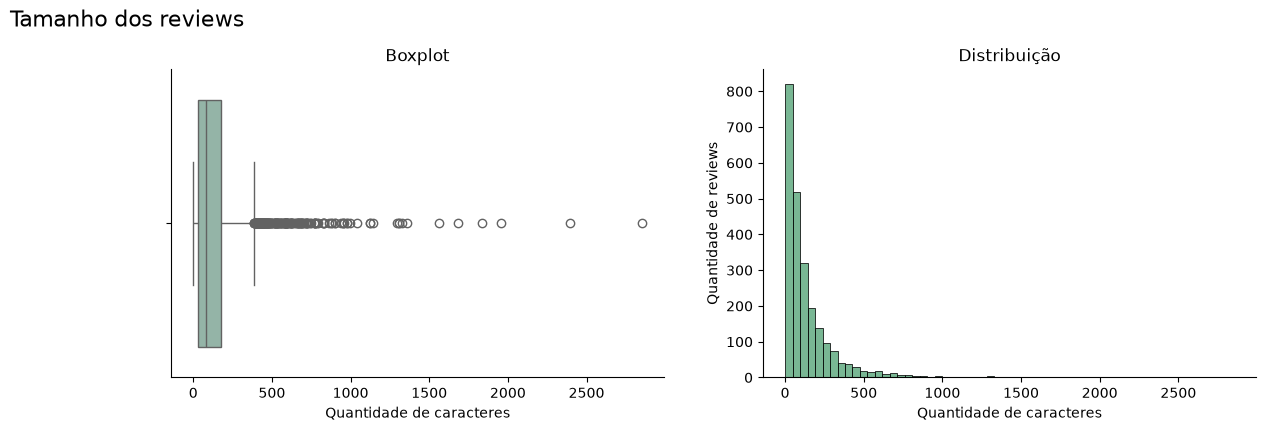

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df_limpo['length'], ax=ax[0], color='#8FB9A8')
ax[0].set(title='Boxplot', xlabel='Quantidade de caracteres')
sns.histplot(df_limpo['length'], bins=60, ax=ax[1], color='#4C9F70')
ax[1].set(title='Distribuição', xlabel='Quantidade de caracteres', ylabel='Quantidade de reviews')
sns.despine()
plt.suptitle('Tamanho dos reviews', fontsize=16, x=0.01, ha='left', y=1.03)
salvar('Tamanho dos reviews')
plt.show()

In [17]:
# O maior e o menor review
display(df_limpo.loc[[df_limpo['length'].idxmax(), df_limpo['length'].idxmin()],
                     ['rating', 'variation', 'length', 'verified_reviews']])

,rating,variation,length,verified_reviews
1632,5,Black Plus,2851,Incredible piece of technology.I have this right center of my living room on an island kitchen counter. The mic and speaker goes in every directio...
60,5,Heather Gray Fabric,1,😍


📌 **Nota**
- 🔎 A maioria dos reviews é curta (mediana de **79 caracteres**), mas há textos de até **2.851 caracteres**.
- 🔎 Pela **regra do IQR**, **180 reviews (7,6%)** passam de **385 caracteres** e são considerados outliers de tamanho.
- ✅ **Decisão:** manter todos. Reviews longos são reais (geralmente clientes explicando um problema em detalhe), e o TF-IDF (Fase 03) já reduz o peso do tamanho do texto.

### 2.7. Verificando o balanceamento da variável alvo

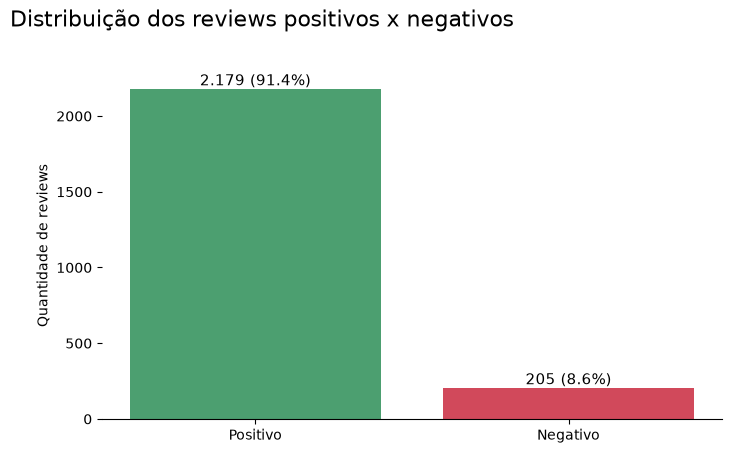

In [18]:
# 1 = review negativo (a classe que queremos encontrar) | 0 = review positivo
df_limpo['negativo'] = 1 - df_limpo['feedback']

plot_distribuicao_alvo(df_limpo['negativo'], 'Distribuição dos reviews positivos x negativos',
                       'Distribuicao positivos x negativos')

📌 **Nota**
- 🔎 Apenas **8,6%** dos reviews são negativos (205 de 2.384): base **desbalanceada**.
- ⚠️ Um modelo que dissesse "todo review é positivo" acertaria **91,4%** e seria inútil. Por isso a **acurácia não serve** como métrica principal, e olhamos a **precisão, o recall e o F1 da classe negativa**.
- ✅ Para facilitar a leitura, invertemos o alvo: **`negativo = 1`** é a classe que queremos encontrar.

### 🛡️ Remoção de variáveis com vazamento (*data leakage*)

**Vazamento** é quando uma variável carrega a **própria resposta** (ou uma informação que só existe depois dela). O modelo fica ótimo no notebook e inútil na prática.

In [19]:
# Listando as variáveis com data leakage
vazamento_colunas = pd.DataFrame({
    'Motivo': ['O rótulo foi criado a partir da nota (1-2 = negativo, 3-5 = positivo)',
               'É o próprio alvo original, invertido em `negativo`'],
    'Correlação com o alvo (Spearman)': [df_limpo[['rating', 'negativo']].corr(method='spearman').iloc[0, 1], -1.0],
}, index=['rating', 'feedback'])
vazamento_colunas.round(3)

,Motivo,Correlação com o alvo (Spearman)
rating,"O rótulo foi criado a partir da nota (1-2 = negativo, 3-5 = positivo)",-0.62
feedback,"É o próprio alvo original, invertido em `negativo`",-1.00


📌 **Nota**
- 🔎 `rating` decide o rótulo sozinha: com ela, o modelo não precisaria ler o texto. Além disso, o objetivo de negócio é classificar textos **sem nota** (ex.: comentários em redes sociais e e-mails).
- ✅ **Decisão:** `rating` e `feedback` ficam **fora** do modelo. A seção 9 da Fase 03 (**teste anti-vazamento**) mostra o que aconteceria se a nota entrasse.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS

A EDA ajuda a entender **como clientes satisfeitos e insatisfeitos escrevem**. Cada hipótese tem um gráfico e uma conclusão.

### 3.1. Criação das Hipóteses

| # | Hipótese | Tipo |
|---|---|---|
| H1 | A maioria dos clientes dá nota máxima (5) | Individual |
| H2 | A maioria dos reviews é curta (menos de 100 caracteres) | Individual |
| H3 | Reviews negativos são mais longos que os positivos | Combinada |
| H4 | Algumas variações do produto concentram mais reviews negativos | Combinada |
| H5 | Palavras de negação ("not", "no") aparecem mais nos reviews negativos | Combinada |
| H6 | Reviews negativos falam de defeitos e funcionamento; os positivos, de uso e diversão | Combinada |

### 3.2. Hipóteses Individuais (colunas isoladas)

#### H1 – A maioria dos clientes dá nota máxima (5)

**Teste.** Binomial: a proporção de notas 5 é maior que 50%? (hipótese individual, sobre uma coluna só)

In [20]:
n_nota5 = (df_limpo['rating'] == 5).sum()
teste_h1 = stats.binomtest(n_nota5, len(df_limpo), 0.5, alternative='greater')
print(f'Notas 5: {n_nota5} de {len(df_limpo)} ({n_nota5 / len(df_limpo):.1%}) | p-valor = {teste_h1.pvalue:.3g}')

Notas 5: 1733 de 2384 (72.7%) | p-valor = 6.77e-113


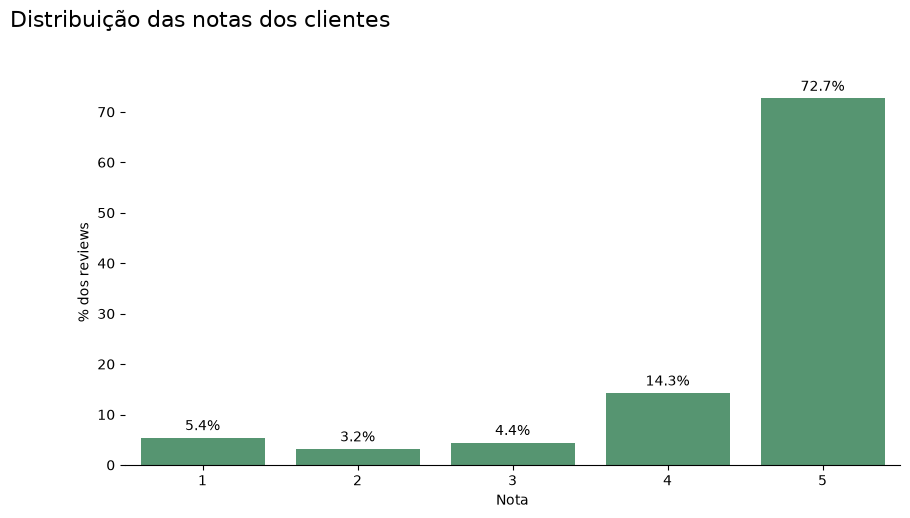

In [21]:
notas = df_limpo['rating'].value_counts(normalize=True).sort_index() * 100
plot_barras(notas, 'Distribuição das notas dos clientes', 'Distribuicao das notas',
            xlabel='Nota', ylabel='% dos reviews', formato='{:.1f}%')

✅ **Verdadeira.** **72,7%** dos reviews têm nota 5, e somando a nota 4 chegam a **87%**. Apenas **8,6%** têm nota 1 ou 2 (os negativos).
- 🔎 **Teste binomial:** p-valor de **6,8 × 10⁻¹¹³**. A proporção de notas 5 é claramente maior que 50%, não é acaso.

#### H2 – A maioria dos reviews é curta (menos de 100 caracteres)

**Teste.** Binomial: a proporção de reviews com menos de 100 caracteres é maior que 50%?

In [22]:
n_curtos = (df_limpo['length'] < 100).sum()
teste_h2 = stats.binomtest(n_curtos, len(df_limpo), 0.5, alternative='greater')
print(f'Reviews com menos de 100 caracteres: {n_curtos / len(df_limpo):.1%} | p-valor = {teste_h2.pvalue:.3g}')

Reviews com menos de 100 caracteres: 57.8% | p-valor = 9.68e-15


✅ **Verdadeira.** **57,8%** dos reviews têm menos de 100 caracteres: a maioria escreve uma ou duas frases curtas (ex.: *"Love my Echo!"*).
- 🔎 **Teste binomial:** p-valor de **9,7 × 10⁻¹⁵**. Mas o tamanho do efeito é modesto: 57,8% é só um pouco acima da metade.

### 3.3. Hipóteses Combinadas (entre colunas)

#### H3 – Reviews negativos são mais longos que os positivos

**Teste.** Mann-Whitney (o tamanho dos reviews difere entre os grupos?), com a **correlação de postos** como tamanho de efeito (de -1 a 1; acima de 0,3 já é moderado).

In [23]:
teste_h3 = teste_mann_whitney(df_limpo.loc[df_limpo['negativo'] == 1, 'length'], df_limpo.loc[df_limpo['negativo'] == 0, 'length'])
pd.Series(teste_h3).to_frame('H3').T

,teste,estatística,p-valor,efeito,tamanho do efeito
H3,Mann-Whitney,304095.0,0.0,correlação de postos,0.361533


,length,n_palavras
Positivo,75.0,14.0
Negativo,163.0,31.0


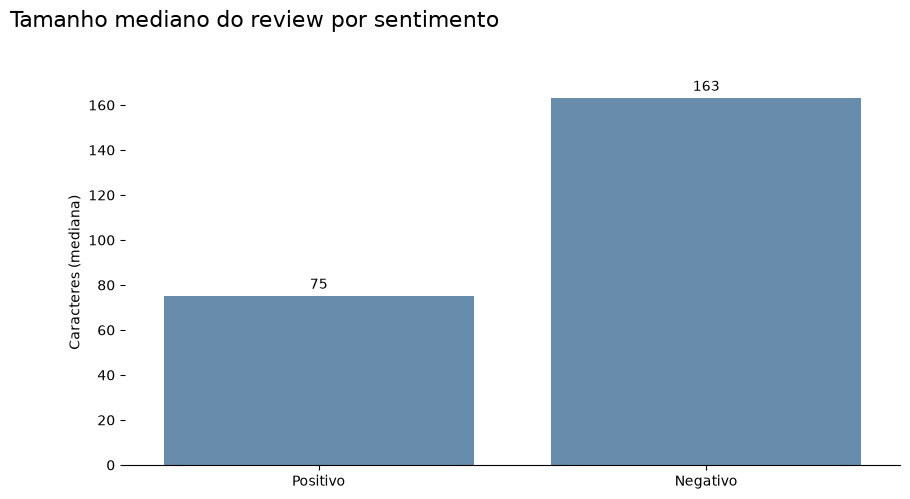

In [24]:
tamanho = df_limpo.groupby('negativo')[['length', 'n_palavras']].median()
tamanho.index = ['Positivo', 'Negativo']
display(tamanho)

plot_barras(tamanho['length'], 'Tamanho mediano do review por sentimento', 'Tamanho por sentimento',
            ylabel='Caracteres (mediana)', cor='#5B8DB8')

✅ **Verdadeira.** O review negativo mediano tem **163 caracteres (31 palavras)**, contra **75 caracteres (14 palavras)** do positivo: **mais que o dobro**. Cliente insatisfeito **explica o problema**, enquanto o satisfeito só elogia.
- 🔎 **Mann-Whitney:** p-valor praticamente zero e **correlação de postos de 0,36**, um efeito **moderado**: o tamanho ajuda, mas não separa sozinho os dois grupos (há muitos reviews negativos curtos).

#### H4 – Algumas variações do produto concentram mais reviews negativos

**Teste.** Qui-quadrado de independência entre a variação e o sentimento, com o **V de Cramér** como medida de força (0 = nenhuma relação; acima de 0,2 já é relevante).

In [25]:
teste_h4 = teste_qui_quadrado(df_limpo['variation'], df_limpo['negativo'])
pd.Series(teste_h4).to_frame('H4').T

,teste,estatística,gl,p-valor,efeito,tamanho do efeito
H4,Qui-quadrado,40.591335,15,0.000369,V de Cramér,0.103617


,reviews,pct_negativos,nota_media
variation,,,
White,87,16.09,4.22
Black,258,13.18,4.25
Black Spot,235,12.77,4.34
White Show,82,12.20,4.30
Black Plus,261,10.34,4.38
White Plus,76,9.21,4.39
White Spot,104,8.65,4.40
Configuration: Fire TV Stick,336,7.44,4.61
Black Dot,247,6.88,4.47


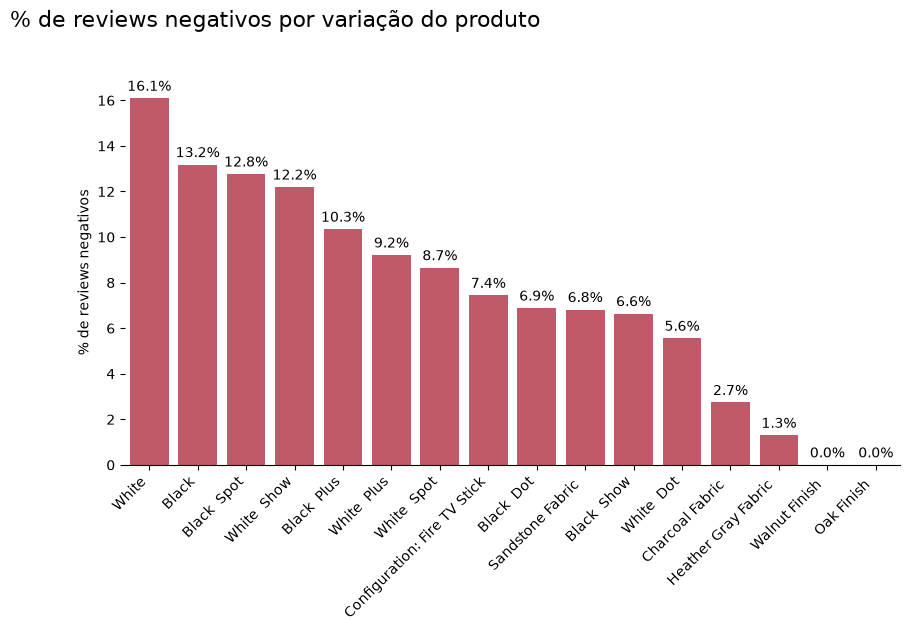

In [26]:
por_variacao = (df_limpo.groupby('variation')
                .agg(reviews=('negativo', 'size'), pct_negativos=('negativo', 'mean'), nota_media=('rating', 'mean'))
                .sort_values('pct_negativos', ascending=False))
por_variacao['pct_negativos'] *= 100
display(por_variacao.round(2))

plot_barras(por_variacao['pct_negativos'], '% de reviews negativos por variação do produto',
            '% negativos por variacao', ylabel='% de reviews negativos', cor='#D1495B', formato='{:.1f}%')

✅ **Verdadeira, com ressalvas.**
- 🔎 **White** (16,1%), **Black** (13,2%) e **Black Spot** (12,8%) têm a maior proporção de reviews negativos.
- 🔎 Os modelos com tecido, **Charcoal Fabric** (2,7%) e **Heather Gray Fabric** (1,3%), quase não recebem críticas.
- 🔎 **Qui-quadrado:** p-valor de **0,0004** (a associação não é acaso), mas o **V de Cramér é só 0,10**: uma associação **fraca**. A variação do produto ajuda pouco a prever o sentimento, como confirmam a seleção de variáveis e a importância por permutação.
- ⚠️ Cada variação corresponde a um **produto diferente** (Echo, Dot, Spot, Show, Plus), então a diferença provavelmente é do **modelo do aparelho**, e não da cor. Algumas variações têm poucos reviews (ex.: Walnut Finish, com 5).

#### H5 – Palavras de negação aparecem mais nos reviews negativos

**Teste.** Qui-quadrado entre ter negação e ser negativo, com o **odds ratio** (quantas vezes a chance de ser negativo é maior quando o review tem negação).

,teste,estatística,gl,p-valor,efeito,tamanho do efeito,odds ratio
H5,Qui-quadrado,191.949531,1,0.0,V de Cramér,0.283072,6.909535


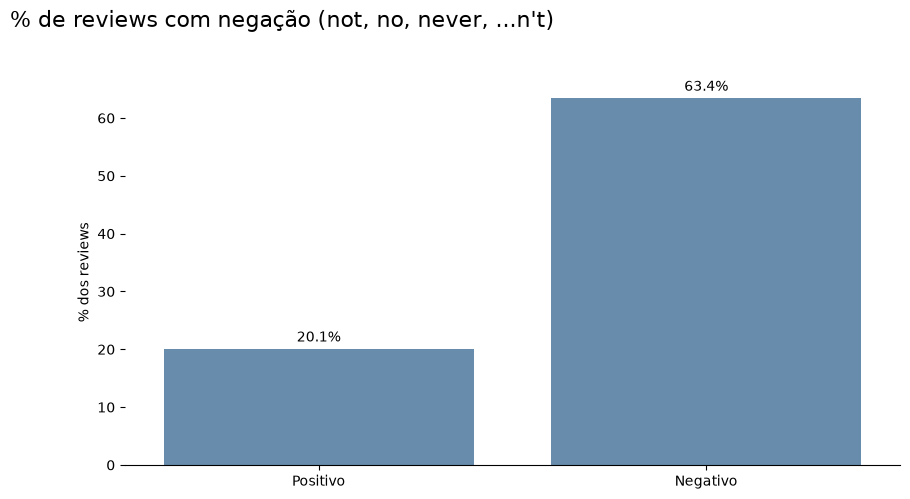

In [27]:
tem_negacao = df_limpo['verified_reviews'].str.lower().str.contains(r"\b(?:not|no|never)\b|n't\b", regex=True)
teste_h5 = teste_qui_quadrado(tem_negacao, df_limpo['negativo'])
teste_h5['odds ratio'] = odds_ratio(tem_negacao, df_limpo['negativo'])
display(pd.Series(teste_h5).to_frame('H5').T)

negacao = tem_negacao.groupby(df_limpo['negativo']).mean() * 100
negacao.index = ['Positivo', 'Negativo']

plot_barras(negacao, '% de reviews com negação (not, no, never, ...n\'t)', 'Negacao por sentimento',
            ylabel='% dos reviews', cor='#5B8DB8', formato='{:.1f}%')

✅ **Verdadeira.** **63,4%** dos reviews negativos têm alguma negação, contra **20,1%** dos positivos: **3 vezes mais**.
- 🔎 **Qui-quadrado:** p-valor praticamente zero, **V de Cramér de 0,28** (associação **relevante**) e **odds ratio de 6,9**: um review com negação tem quase **7 vezes mais chance** de ser negativo. É o efeito mais forte entre as hipóteses.

> 💡 Isso justifica uma decisão importante da limpeza do texto: **não remover as negações** (*not*, *no*), que a versão original eliminava junto com as stopwords.

#### H6 – Reviews negativos falam de defeitos e funcionamento

**Teste.** Comparação descritiva das palavras mais frequentes (sem teste estatístico: são centenas de palavras, e a relevância de cada uma é medida na seleção de variáveis da Fase 03).

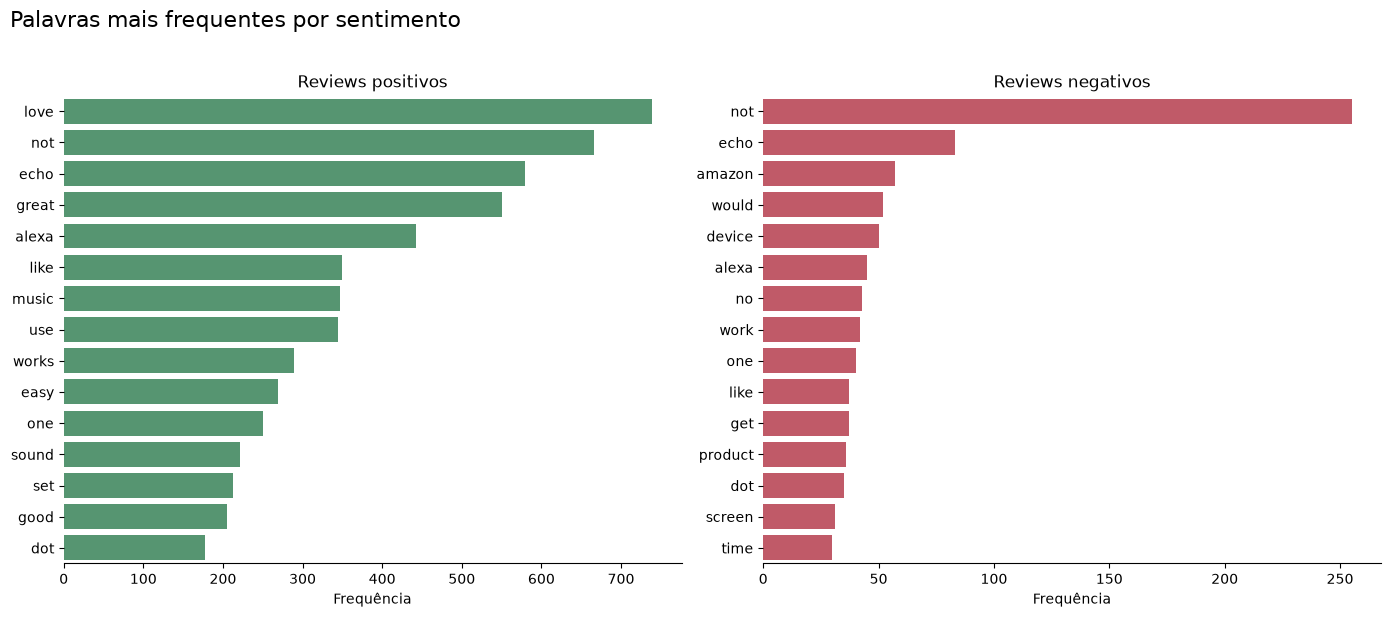

In [28]:
df_limpo['texto_limpo'] = df_limpo['verified_reviews'].apply(limpar_texto)

def palavras_mais_frequentes(textos, n=15):
    contador = CountVectorizer()
    matriz = contador.fit_transform(textos)
    return pd.Series(np.asarray(matriz.sum(axis=0)).ravel(),
                     index=contador.get_feature_names_out()).sort_values(ascending=False).head(n)

top_positivas = palavras_mais_frequentes(df_limpo.loc[df_limpo['negativo'] == 0, 'texto_limpo'])
top_negativas = palavras_mais_frequentes(df_limpo.loc[df_limpo['negativo'] == 1, 'texto_limpo'])

plot_top_palavras(top_positivas, top_negativas, 'Palavras mais frequentes por sentimento', 'Top palavras por sentimento')

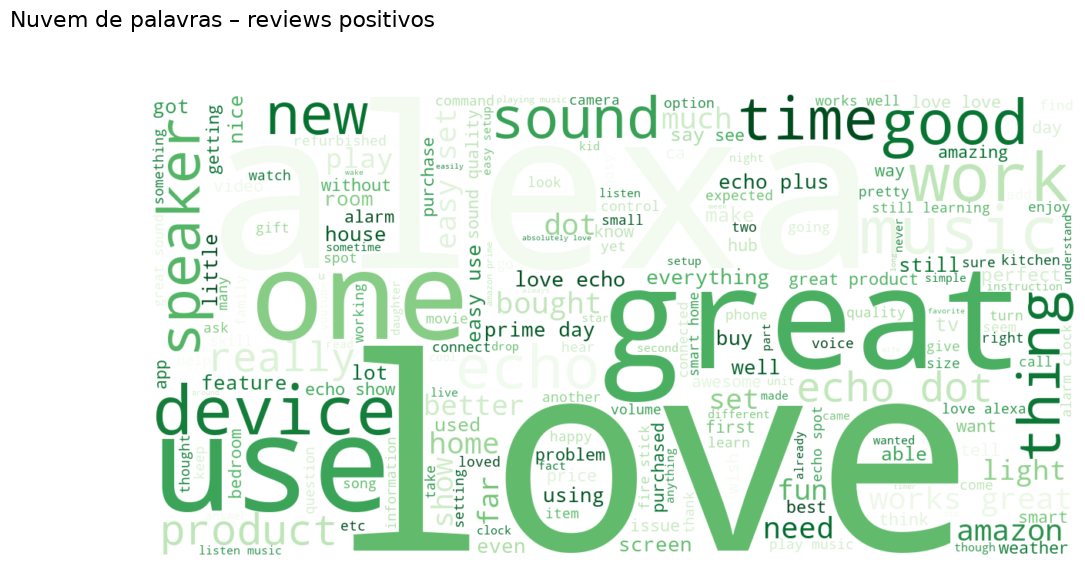

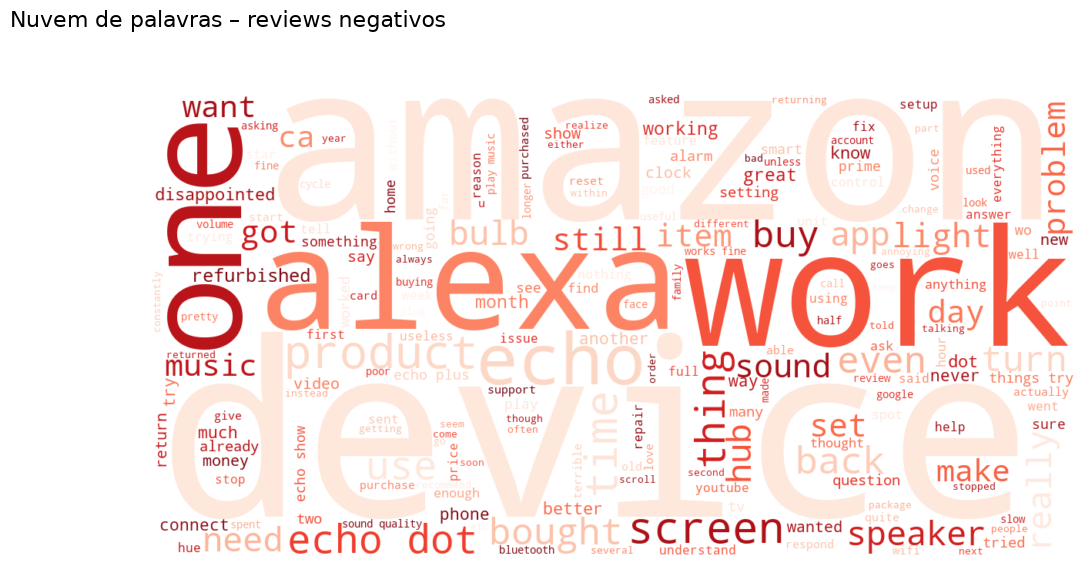

In [29]:
plot_nuvem(' '.join(df_limpo.loc[df_limpo['negativo'] == 0, 'texto_limpo']),
           'Nuvem de palavras – reviews positivos', 'Nuvem de palavras positivas', cor='Greens')
plot_nuvem(' '.join(df_limpo.loc[df_limpo['negativo'] == 1, 'texto_limpo']),
           'Nuvem de palavras – reviews negativos', 'Nuvem de palavras negativas', cor='Reds')

⚠️ **Parcialmente verdadeira.**
- 🔎 Palavras genéricas (*echo*, *alexa*, *one*) aparecem nos dois lados, porque descrevem o produto.
- 🔎 Nos **positivos** se destacam palavras de uso e satisfação: *love*, *great*, *music*, *easy*, *works*, *sound*.
- 🔎 Nos **negativos** aparecem *device*, *work*, *product*, *screen*, *amazon*: o cliente fala do **aparelho e do funcionamento**.
- 🔎 *not* é a palavra mais frequente dos reviews negativos e a 2ª dos positivos (ex.: *"not disappointed"*). Por isso o modelo precisa olhar o **conjunto das palavras**, e não uma palavra isolada.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Teste (tamanho do efeito) | Evidência |
|---|---|---|---|---|
| H1 | A maioria dá nota 5 | ✅ Verdadeira | Binomial (p < 0,001) | 72,7% dos reviews |
| H2 | A maioria dos reviews é curta | ✅ Verdadeira | Binomial (p < 0,001) | 57,8% com menos de 100 caracteres |
| H3 | Negativos são mais longos | ✅ Verdadeira | Mann-Whitney (efeito **0,36**, moderado) | Mediana de 163 x 75 caracteres |
| H4 | Algumas variações têm mais negativos | ✅ Com ressalvas | Qui-quadrado (V de Cramér **0,10**, fraco) | White 16,1% x Charcoal Fabric 2,7% (diferença de produto) |
| H5 | Negações aparecem mais nos negativos | ✅ Verdadeira | Qui-quadrado (V **0,28**; odds ratio **6,9**) | 63,4% x 20,1% |
| H6 | Negativos falam de defeitos/funcionamento | ⚠️ Parcial | Descritivo | *device*, *work*, *screen* x *love*, *great*, *easy* |

> 💡 **Para o modelo:** o **texto** carrega quase toda a informação, e as **negações** são o sinal mais forte (H5). A variação do produto tem associação fraca (H4) e entra só como informação complementar.

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Como foi criada | Uso |
|---|---|---|
| `negativo` | `1 - feedback` | **Alvo** do modelo (1 = review negativo) |
| `length`, `n_palavras` | Nº de caracteres e de palavras | Apenas para a EDA |
| `texto_limpo` | `limpar_texto(verified_reviews)` | EDA (frequência de palavras). No modelo, a limpeza roda **dentro do pipeline** |

**Como funciona a limpeza (`limpar_texto`)**
1. Decodifica códigos HTML (alguns reviews trazem aspas como `&#34;`) e coloca tudo em minúsculas.
2. Transforma contrações negativas em "not" (*don't* → *do not*, *isn't* → *is not*).
3. Remove pontuação, números soltos de símbolos e emojis.
4. Remove **stopwords** (palavras muito comuns que não indicam sentimento, como *the*, *is*, *my*), **exceto as negações** *not*, *no* e *nor*.

> 💡 **Por que manter as negações?** Sem elas, *"it does **not** work"* e *"it works"* ficariam praticamente iguais para o modelo. A versão original removia essas palavras.

In [30]:
# Antes x depois da limpeza
df_limpo[['verified_reviews', 'texto_limpo']].sample(5, random_state=7)

,verified_reviews,texto_limpo
241,Good sound. Like it for music and scheduling. Like that i can get random thoughts recorded while I think about them. The jokes are cute!,good sound like music scheduling like get random thoughts recorded think jokes cute
1042,Very good,good
943,I love love love it.,love love love
395,Perfect condition! I love my echo,perfect condition love echo
194,I love it!,love


## 5 - EXPLORANDO AS CORRELAÇÕES

Como a base tem poucas colunas numéricas, a correlação ajuda a confirmar duas coisas: a relação entre a **nota** e o **rótulo**, e se o **tamanho do texto** tem relação com o sentimento.

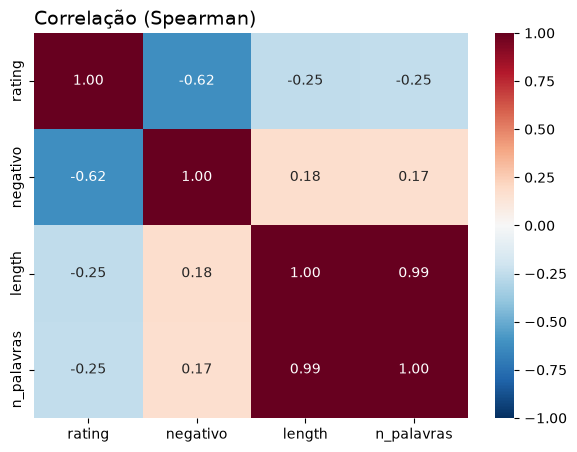

In [31]:
corr = df_limpo[['rating', 'negativo', 'length', 'n_palavras']].corr(method='spearman')

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlação (Spearman)', fontsize=14, loc='left')
salvar('Correlacao')
plt.show()

📌 **Nota**
- 🔎 `rating` × `negativo` = **-0,62**: esperado, já que o rótulo foi criado a partir da nota (por isso `rating` fica fora do modelo).
- 🔎 `length` × `negativo` = **+0,18**: reviews negativos tendem a ser mais longos (H3), mas a relação é **fraca**. O tamanho sozinho não identifica um review negativo; o que importa é **o que está escrito**.
- 🔎 `length` × `n_palavras` = **0,99**: medem praticamente a mesma coisa (por isso foram usadas só na EDA).

# FASE 03: MODELAGEM DOS DADOS

Agora vamos ensinar o computador a diferenciar reviews positivos de negativos. Para isso, o texto precisa virar **números**, e o modelo é escolhido pela capacidade de **encontrar os reviews negativos**.

## 1 - Leitura dos dados

Usamos apenas o que estaria disponível no momento de um review novo: o **texto** e a **variação do produto**. `rating` fica de fora (é a origem do rótulo), assim como `date`, `length` e `n_palavras`.

In [32]:
X = df_limpo[['verified_reviews', 'variation']]
y = df_limpo['negativo']

print(f'X: {X.shape} | y: {y.shape} | % negativos: {y.mean():.1%}')

X: (2384, 2) | y: (2384,) | % negativos: 8.6%


## 2 - Valores nulos

In [33]:
X.isnull().sum()

verified_reviews    0
variation           0
dtype: int64

✅ Nenhum valor nulo: os textos vazios já foram removidos na Fase 02.

## 3 - Transformação

Modelos não leem texto, então transformamos cada review em números com o **TF-IDF**:

| Etapa | O que faz |
|---|---|
| **Vocabulário** | Lista todas as palavras (e pares de palavras, como *"not working"*) que aparecem nos reviews de treino |
| **TF (frequência no review)** | Conta quantas vezes cada palavra aparece no review |
| **IDF (raridade na base)** | Dá **mais peso a palavras raras** e menos a palavras que aparecem em todo lugar (como *"echo"*) |

> 💡 **Analogia:** o TF-IDF funciona como um marca-texto: destaca as palavras que realmente diferenciam um review dos outros.

A variação do produto (`variation`) entra com **One-Hot Encoding** (uma coluna 0/1 por variação). As duas transformações ficam juntas em um `ColumnTransformer`.

In [34]:
def criar_preprocessador(ngram_range=(1, 2), min_df=2):
    return ColumnTransformer([
        ('texto', TfidfVectorizer(preprocessor=limpar_texto, ngram_range=ngram_range, min_df=min_df),
         'verified_reviews'),
        ('variacao', OneHotEncoder(handle_unknown='ignore'), ['variation']),
    ])

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

Antes de treinar, os dados são divididos em **três partes**, como numa preparação para uma prova:

| Conjunto | Tamanho | Para que serve | Comparação |
|---|---|---|---|
| **Treino** | 60% | o modelo **aprende** os padrões | estudar a matéria |
| **Validação** | 20% | **comparar** algoritmos, ajustar configurações e escolher o limiar | fazer simulados |
| **Teste** | 20% | **avaliação final**, usada uma única vez no fim | a prova de verdade |

O `stratify` garante que as três partes tenham **a mesma proporção** de reviews negativos.

In [35]:
# Primeira divisão: separar o conjunto de teste (20%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

# Segunda divisão: do restante (80%), separar treino (75%) e validação (25%) -> 60% / 20% / 20%
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=SEED, stratify=y_temp)

pd.DataFrame({
    'Reviews': [len(X), len(X_train), len(X_val), len(X_test)],
    '% da base': [1, len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    'Negativos': [y.sum(), y_train.sum(), y_val.sum(), y_test.sum()],
    '% negativos': [y.mean(), y_train.mean(), y_val.mean(), y_test.mean()],
}, index=['Dados originais', 'Treino', 'Validação', 'Teste']).style.format(
    {'% da base': '{:.0%}', '% negativos': '{:.1%}'})

,Reviews,% da base,Negativos,% negativos
Dados originais,2384,100%,205,8.6%
Treino,1430,60%,123,8.6%
Validação,477,20%,41,8.6%
Teste,477,20%,41,8.6%


📌 **Nota**
- 🔎 **Treino: 1.430 reviews (60%)**, com os quais os algoritmos aprendem; **validação: 477 (20%)**, para compará-los e escolher o limiar; **teste: 477 (20%)**, guardados até o fim.
- 🔎 A proporção de negativos é a mesma nas três partes (**8,6%**), efeito do `stratify`. Na validação e no teste são **41 reviews negativos** em cada.
- ⚠️ 41 negativos é pouco: um único acerto a mais muda o recall em **2,4 pontos percentuais**. Por isso, a comparação dos algoritmos é **complementada por validação cruzada** (média ± desvio).

### 4.2. Balancear os dados

**Balancear** é deixar as duas classes com a **mesma quantidade** de exemplos no treino. Com só ~9% de negativos, um modelo tende a "ignorar" essa classe. Usamos duas formas de compensar:

| Técnica | Como funciona | Onde usamos |
|---|---|---|
| **SMOTE** | Cria reviews negativos **sintéticos** (combinações dos existentes) até igualar as classes | Treino dos algoritmos da seção 5 |
| **`class_weight='balanced'`** | Não cria dados: diz ao modelo que **errar um negativo custa mais** | Ajuste fino da Regressão Logística (seção 7) |

> ⚠️ O balanceamento é aplicado **só no treino**, e **depois** da transformação em números. A validação e o teste ficam com a **distribuição real** (9% de negativos), que é a que o modelo vai encontrar no dia a dia.

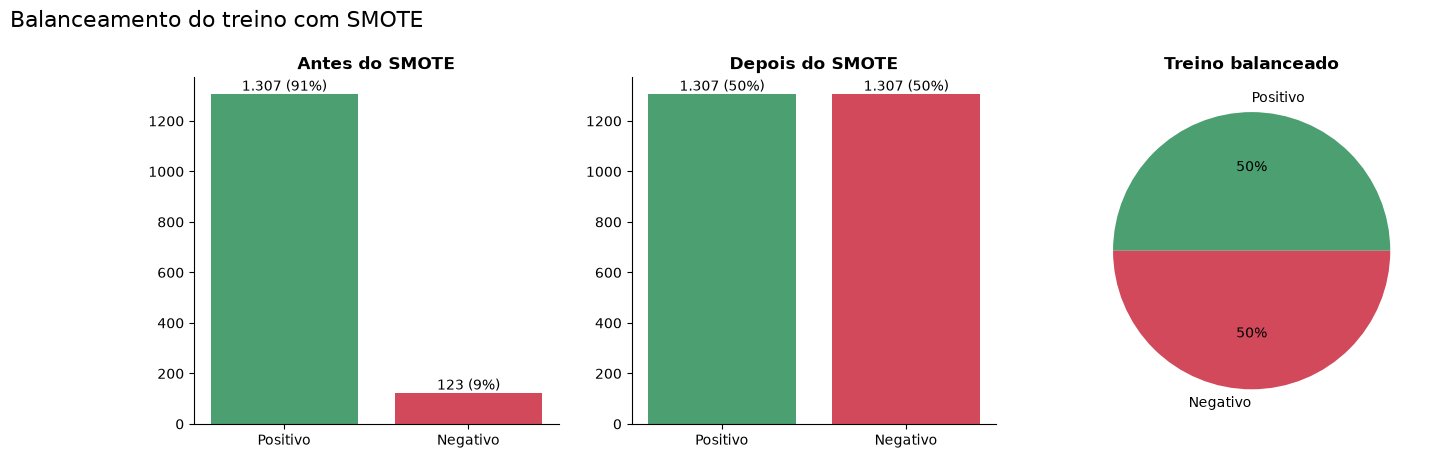

treino original ..... (1430, 3047) | 8.6% negativos
treino balanceado ... (2614, 3047) | 50% negativos
validação ........... (477, 3047) | 8.6% negativos (distribuição real)


In [36]:
# Transformando o treino em números (ajuste só no treino original, sem dados sintéticos)
prep_sel = criar_preprocessador()
X_train_t = prep_sel.fit_transform(X_train)
X_val_t = prep_sel.transform(X_val)          # mesma transformação, sem reajustar
nomes_t = [nome.split('__')[-1] for nome in prep_sel.get_feature_names_out()]

# Balanceamento (SMOTE) aplicado à matriz transformada do treino
X_train_balanced_t, y_train_balanced = SMOTE(random_state=SEED).fit_resample(X_train_t, y_train)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, serie, titulo_grafico in [(axs[0], y_train, 'Antes do SMOTE'), (axs[1], y_train_balanced, 'Depois do SMOTE')]:
    contagem = pd.Series(serie).value_counts().sort_index()
    barras = ax.bar(['Positivo', 'Negativo'], contagem.values, color=['#4C9F70', '#D1495B'])
    ax.bar_label(barras, labels=[f'{v:,} ({v / contagem.sum():.0%})'.replace(',', '.') for v in contagem.values])
    ax.set_title(titulo_grafico, fontweight='bold')
    sns.despine(ax=ax)
axs[2].pie(pd.Series(y_train_balanced).value_counts().sort_index(), labels=['Positivo', 'Negativo'],
           autopct='%1.0f%%', colors=['#4C9F70', '#D1495B'])
axs[2].set_title('Treino balanceado', fontweight='bold')
plt.suptitle('Balanceamento do treino com SMOTE', fontsize=16, x=0.01, ha='left', y=1.03)
salvar('Balanceamento SMOTE')
plt.show()

print(f'treino original ..... {X_train_t.shape} | {y_train.mean():.1%} negativos')
print(f'treino balanceado ... {X_train_balanced_t.shape} | {y_train_balanced.mean():.0%} negativos')
print(f'validação ........... {X_val_t.shape} | {y_val.mean():.1%} negativos (distribuição real)')

📌 **Nota**
- 🔎 O treino passa de **1.430 para 2.614 reviews**: o SMOTE cria **1.184 reviews negativos sintéticos** até que as classes fiquem **50% / 50%**.
- 🔎 A validação continua com os **477 reviews reais** (8,6% de negativos): é nela que medimos como o modelo se sairia no dia a dia.

### 4.3. Seleção de Variáveis

Em textos, cada palavra vira uma variável. Usamos `min_df` para **descartar palavras raras** (que aparecem em menos de `min_df` reviews), que geralmente são erros de digitação ou ruído.

In [37]:
for min_df in [1, 2, 3]:
    vetorizador = TfidfVectorizer(preprocessor=limpar_texto, ngram_range=(1, 2), min_df=min_df)
    vetorizador.fit(X_train['verified_reviews'])
    print(f'min_df={min_df}: {len(vetorizador.vocabulary_):>6,} palavras/pares de palavras no vocabulário')

min_df=1: 17,640 palavras/pares de palavras no vocabulário


min_df=2:  3,031 palavras/pares de palavras no vocabulário


min_df=3:  1,656 palavras/pares de palavras no vocabulário


📌 **Nota**
- 🔎 Com `min_df=1`, o vocabulário do treino tem **17.640 termos**. Exigindo que o termo apareça em pelo menos 2 reviews, cai para **3.031 (-83%)**: a grande maioria dos termos aparece **uma única vez** (erros de digitação, nomes, pares de palavras raros).
- ✅ O valor ideal de `min_df` é escolhido no **ajuste fino** (item 7), junto com os outros hiperparâmetros.

#### Relevância de cada variável: Random Forest e Informação Mútua

Nem toda variável ajuda o modelo da mesma forma. Esta etapa mede a relevância de cada uma usando dois métodos diferentes, que olham o problema por ângulos distintos:

| Método | Como funciona | Em palavras simples |
|---|---|---|
| **Random Forest** | treina várias árvores de decisão e mede o quanto cada variável ajuda a separar as classes | "quais perguntas o modelo mais usou para decidir" |
| **Informação Mútua** | mede o quanto conhecer a variável reduz a incerteza sobre o alvo | "quanto essa palavra, sozinha, conta sobre o sentimento" |

> Um cuidado técnico: os dois métodos só aceitam números. Por isso usamos a **matriz transformada** do item 4.2 (pré-processador ajustado só no treino original) e a sua versão **balanceada** pelo SMOTE. Na Informação Mútua, cada palavra é medida pela **presença** no review (aparece ou não), uma forma mais estável de comparar milhares de palavras.

not         0.0676
work        0.0271
no          0.0226
not work    0.0187
love        0.0177
amazon      0.0169
would       0.0164
back        0.0136
get         0.0122
try         0.0119
wanted      0.0115
great       0.0114
return      0.0110
device      0.0107
time        0.0090
sucks       0.0074
one         0.0070
product     0.0068
working     0.0064
already     0.0063


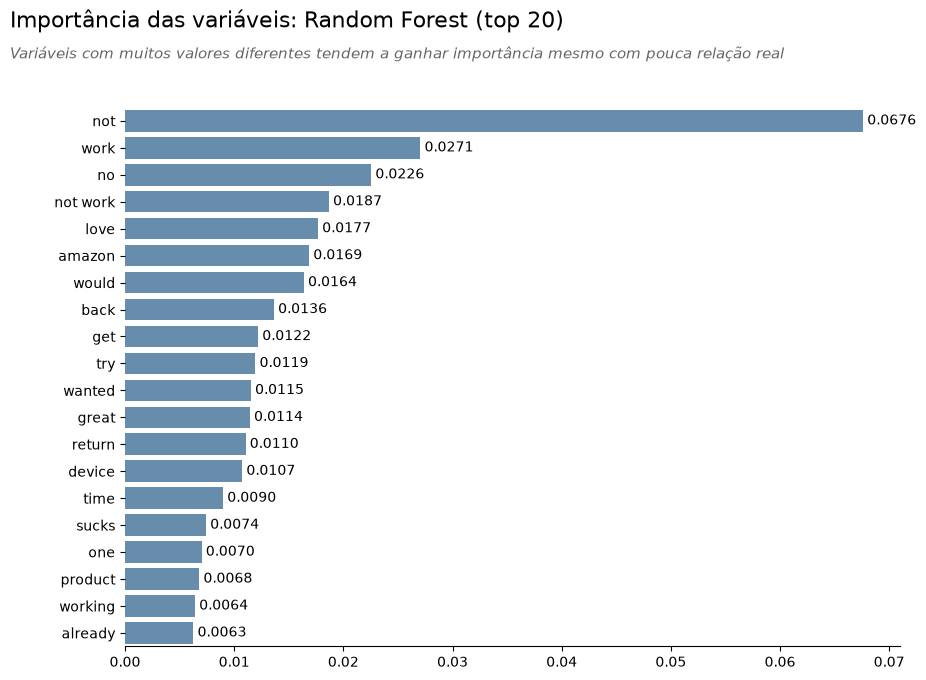

In [38]:
# Random Forest - classificação das melhores variáveis
importances = importancia_random_forest(X_train_balanced_t, y_train_balanced, nomes_t, semente=SEED)
print(importances.head(20).round(4).to_string())

plot_barras(importances.head(20), 'Importância das variáveis: Random Forest (top 20)',
            'Importancia RF (selecao)', horizontal=True, cor='#5B8DB8', formato='{:.4f}',
            subtitulo='Variáveis com muitos valores diferentes tendem a ganhar importância mesmo com pouca relação real')

informação mútua calculada em 23s

🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de 3,047):
     feature   score
0        not  0.2229
1       work  0.1093
2     amazon  0.0833
3   not work  0.0741
4         no  0.0703
5      would  0.0686
6       back  0.0636
7     device  0.0616
8        try  0.0610
9        get  0.0608
10       one  0.0480
11    return  0.0479
12    wanted  0.0446
13   product  0.0410
14      easy  0.0409
15      turn  0.0392
16      even  0.0383
17   working  0.0375
18      love  0.0359
19      half  0.0357

colunas com informação mútua igual a zero: 6 de 3,047

🏆 TOP 5 FEATURES SELECIONADAS:
1. not: 0.222887
2. work: 0.109317
3. amazon: 0.083285
4. not work: 0.074123
5. no: 0.070273

📊 Shape original: (2614, 3047)
📊 Shape após seleção: (2614, 5)
📊 Features selecionadas: ['not', 'work', 'amazon', 'not work', 'no']


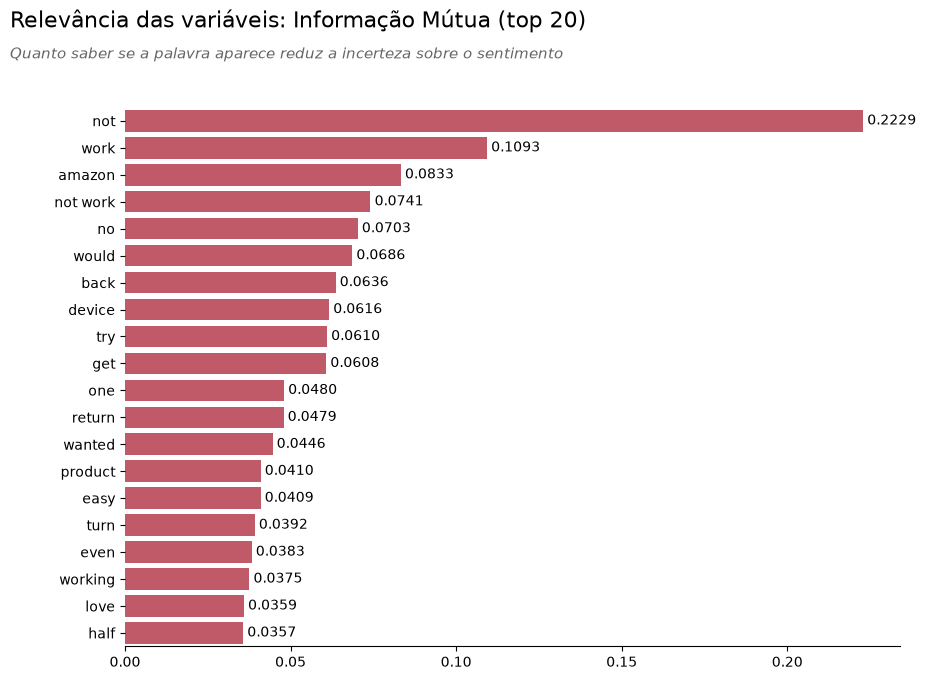

In [39]:
# Informação Mútua - ranking de todas as colunas e seleção das 5 melhores
t0 = time.time()
df_scores, selector = selecao_features(X_train_balanced_t, y_train_balanced, nomes_t, k=5, semente=SEED)
print(f'informação mútua calculada em {time.time() - t0:.0f}s\n')

print(f'🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de {len(nomes_t):,}):')
print('=' * 50)
print(df_scores.head(20).round(4).to_string())
print(f"\ncolunas com informação mútua igual a zero: {(df_scores['score'] == 0).sum()} de {len(df_scores):,}")

print('\n🏆 TOP 5 FEATURES SELECIONADAS:')
print('=' * 50)
top_5_features = df_scores.head(5)['feature'].tolist()
for i, (feature, score) in enumerate(df_scores.head(5).itertuples(index=False), 1):
    print(f'{i}. {feature}: {score:.6f}')

X_train_selected = selector.transform(X_train_balanced_t)
print(f'\n📊 Shape original: {X_train_balanced_t.shape}')
print(f'📊 Shape após seleção: {X_train_selected.shape}')
print(f'📊 Features selecionadas: {top_5_features}')

plot_barras(df_scores.head(20).set_index('feature')['score'], 'Relevância das variáveis: Informação Mútua (top 20)',
            'Informacao mutua', horizontal=True, cor='#D1495B', formato='{:.4f}',
            subtitulo='Quanto saber se a palavra aparece reduz a incerteza sobre o sentimento')

In [40]:
# Comparação dos dois rankings (top 20 de cada método)
pd.DataFrame({'Random Forest': importances.head(20).index,
              'Informação Mútua': df_scores.head(20)['feature'].values}, index=range(1, 21))

,Random Forest,Informação Mútua
1,not,not
2,work,work
3,no,amazon
4,not work,not work
5,love,no
6,amazon,would
7,would,back
8,back,device
9,get,try
10,try,get


📌 **Nota**
- 🔎 O treino transformado tem **3.047 colunas** (3.031 palavras e pares de palavras + 16 variações do produto).
- 🔎 Os dois métodos concordam no principal: **"not"** é, de longe, a variável mais relevante (Random Forest **0,068**; Informação Mútua **0,223**, o dobro da 2ª colocada). Isso confirma a decisão de **manter as negações** na limpeza do texto (a versão original as removia).
- 🔎 Em seguida vêm palavras de **defeito e devolução**: *work*, *not work*, *no*, *back*, *return*, *try*, *device*, *wanted*. Palavras positivas como *love*, *great* e *easy* também aparecem: elas ajudam a separar as classes pela **ausência** nos reviews negativos.
- 🔎 Nenhuma **variação do produto** está entre as 20 mais relevantes (confirma a H4). Só **6 de 3.047** colunas têm informação mútua igual a zero.
- ✅ **Decisão:** **não cortar** o vocabulário para as 5 melhores palavras. Com milhares de palavras, cada uma contribui um pouco, e a regularização da Regressão Logística (`C`, item 7) já reduz o peso das palavras pouco úteis. O tamanho do vocabulário é definido pelo `min_df` no ajuste fino.

## 5 - Treinamento dos Algoritmos de Machine Learning

**Treinar** um algoritmo é mostrar a ele exemplos (os reviews do treino, com a resposta) para que ele aprenda os padrões. Depois, pedimos que ele **preveja** reviews que nunca viu (a **validação**) e comparamos as previsões com a resposta verdadeira (o **gabarito**).

Todos os algoritmos treinam com o **treino balanceado** (matriz transformada + SMOTE) e são avaliados na **validação real**.

**Como vamos medir o desempenho** (a classe de interesse é **1 = review negativo**):

| Métrica | Pergunta que ela responde |
|---|---|
| **Acurácia** | De todos os reviews, quantos o modelo acertou? |
| **Precisão** | Dos reviews que o modelo apontou como negativos, quantos eram negativos de verdade? |
| **Recall** | De todos os reviews negativos, quantos o modelo encontrou? |
| **F1-Score** | Um equilíbrio entre precisão e recall |
| **AUC-ROC** | O modelo sabe ordenar quem é mais negativo? (0,5 = sorteio, 1,0 = perfeito) |
| **PR-AUC** | Como a anterior, mas focada na classe negativa (sorteio ≈ 0,09, a proporção de negativos) |

**Réguas de comparação:** um "modelo" que dissesse **sempre "positivo"** acertaria **~91%** dos reviews, mas não encontraria nenhum negativo. E um sorteio teria **AUC de 0,50** e **PR-AUC de ~0,09**. Todo resultado precisa superar isso.

Cada algoritmo é avaliado pela função `relatorio_validacao` (`src/avaliacao.py`), que mostra sempre as mesmas peças: amostra gabarito × probabilidade × previsão, métricas, **AUC no treino × validação** (para detectar **sobreajuste**), relatório de classificação e matriz de confusão.

### XGBoost

O **XGBoost** constrói **centenas de árvores de decisão em sequência**. Cada nova árvore olha para os erros das anteriores e tenta corrigi-los, como um grupo de professores em que cada um revisa a correção do colega anterior.

XGBoost treinado em 6.3s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.010,0
1,0,0.052,0
2,0,0.033,0
3,0,0.016,0
4,0,0.001,0
5,0,0.000,0
6,0,0.031,0
7,0,0.009,0


MÉTRICAS DE VALIDAÇÃO: XGBoost
Acurácia                 0.9078
Precisão                 0.4483
Recall (Sensibilidade)   0.3171
F1-Score                 0.3714
AUC-ROC                  0.8741
PR-AUC                   0.4176
                         (sorteio: PR-AUC = 0.0860, AUC-ROC = 0,50)

AUC-ROC no treino: 0.9980 | na validação: 0.8741 | diferença: +0.1239

              precision    recall  f1-score   support

Positivo (0)     0.9375    0.9633    0.9502       436
Negativo (1)     0.4483    0.3171    0.3714        41

    accuracy                         0.9078       477
   macro avg     0.6929    0.6402    0.6608       477
weighted avg     0.8954    0.9078    0.9005       477



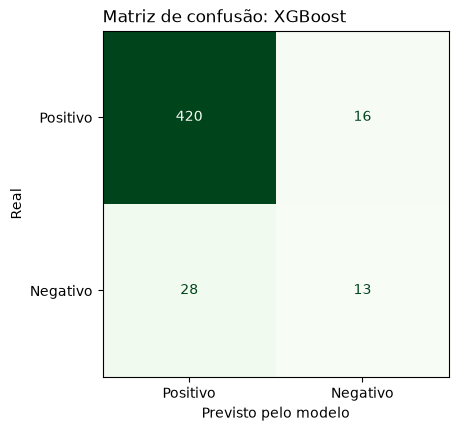

In [41]:
model_xgb = xgb.XGBClassifier(random_state=SEED, eval_metric='logloss')

t0 = time.time()
model_xgb.fit(X_train_balanced_t, y_train_balanced)   # treino BALANCEADO
print(f'XGBoost treinado em {time.time() - t0:.1f}s\n')

# Avaliação na VALIDAÇÃO (dados NÃO balanceados); o AUC de treino usa o treino original, sem cópias
metricas_xgb, proba_xgb = relatorio_validacao('XGBoost', model_xgb, X_train_t, y_train, X_val_t, y_val)

📌 **Nota**
- 🔎 **Recall de 31,7%:** o XGBoost encontra só **13 dos 41** reviews negativos com o limiar de 0,50. A precisão é de 44,8%.
- 🔎 **PR-AUC de 0,418** (sorteio = 0,086) e **AUC-ROC de 0,874**: há sinal, mas é o modelo que **pior ordena** os reviews.
- ⚠️ **Sobreajuste:** AUC de **0,998 no treino** contra **0,874 na validação**. As árvores decoram detalhes dos reviews do treino (incluindo os sintéticos do SMOTE), que não se repetem em reviews novos. Com milhares de colunas esparsas e poucos negativos, modelos de árvore têm dificuldade com texto.

### Random Forest

O **Random Forest** treina **centenas de árvores independentes**, cada uma com uma parte dos dados e das palavras, e decide pela **votação** entre elas, como pedir a opinião de vários especialistas.

Random Forest treinado em 1.1s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.17,0
1,0,0.08,0
2,0,0.12,0
3,0,0.08,0
4,0,0.00,0
5,0,0.05,0
6,0,0.00,0
7,0,0.01,0


MÉTRICAS DE VALIDAÇÃO: Random Forest
Acurácia                 0.9078
Precisão                 0.4118
Recall (Sensibilidade)   0.1707
F1-Score                 0.2414
AUC-ROC                  0.9066
PR-AUC                   0.4048
                         (sorteio: PR-AUC = 0.0860, AUC-ROC = 0,50)



AUC-ROC no treino: 1.0000 | na validação: 0.9066 | diferença: +0.0934

              precision    recall  f1-score   support

Positivo (0)     0.9261    0.9771    0.9509       436
Negativo (1)     0.4118    0.1707    0.2414        41

    accuracy                         0.9078       477
   macro avg     0.6689    0.5739    0.5961       477
weighted avg     0.8819    0.9078    0.8899       477



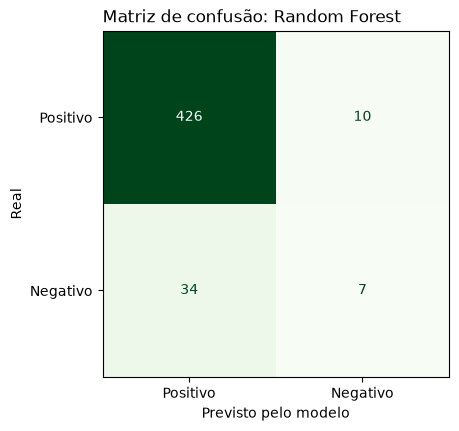

In [42]:
model_rf = RandomForestClassifier(random_state=SEED, n_jobs=-1)

t0 = time.time()
model_rf.fit(X_train_balanced_t, y_train_balanced)   # treino BALANCEADO
print(f'Random Forest treinado em {time.time() - t0:.1f}s\n')

# Avaliação na VALIDAÇÃO (dados NÃO balanceados); o AUC de treino usa o treino original, sem cópias
metricas_rf, proba_rf = relatorio_validacao('Random Forest', model_rf, X_train_t, y_train, X_val_t, y_val)

📌 **Nota**
- 🔎 **Recall de 17,1%:** o Random Forest encontra só **7 dos 41** negativos. Com o limiar de 0,50, ele quase sempre diz "positivo".
- 🔎 O AUC-ROC (**0,907**) é bom, mas a PR-AUC (**0,405**) é a **mais baixa**: ele ordena bem os reviews claramente positivos, mas não os negativos.
- ⚠️ **Sobreajuste máximo:** AUC de **1,000 no treino** (acerta tudo o que já viu) contra 0,907 na validação.

### LightGBM

O **LightGBM** segue a mesma ideia do XGBoost (árvores em sequência), mas cresce cada árvore pelo galho mais promissor, o que o deixa **mais rápido**.

LightGBM treinado em 3.1s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.001,0
1,0,0.002,0
2,0,0.004,0
3,0,0.003,0
4,0,0.000,0
5,0,0.000,0
6,0,0.003,0
7,0,0.001,0


MÉTRICAS DE VALIDAÇÃO: LightGBM
Acurácia                 0.9266
Precisão                 0.6154
Recall (Sensibilidade)   0.3902
F1-Score                 0.4776
AUC-ROC                  0.9093
PR-AUC                   0.5449
                         (sorteio: PR-AUC = 0.0860, AUC-ROC = 0,50)

AUC-ROC no treino: 1.0000 | na validação: 0.9093 | diferença: +0.0907

              precision    recall  f1-score   support

Positivo (0)     0.9446    0.9771    0.9605       436
Negativo (1)     0.6154    0.3902    0.4776        41

    accuracy                         0.9266       477
   macro avg     0.7800    0.6837    0.7191       477
weighted avg     0.9163    0.9266    0.9190       477



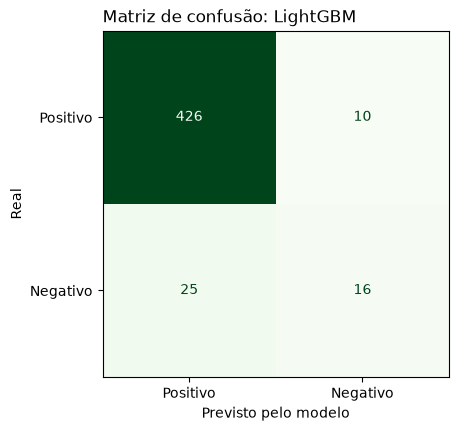

In [43]:
model_lgbm = lgb.LGBMClassifier(random_state=SEED, verbose=-1)

t0 = time.time()
model_lgbm.fit(X_train_balanced_t, y_train_balanced)   # treino BALANCEADO
print(f'LightGBM treinado em {time.time() - t0:.1f}s\n')

# Avaliação na VALIDAÇÃO (dados NÃO balanceados); o AUC de treino usa o treino original, sem cópias
metricas_lgbm, proba_lgbm = relatorio_validacao('LightGBM', model_lgbm, X_train_t, y_train, X_val_t, y_val)

📌 **Nota**
- 🔎 O LightGBM tem a **maior precisão (61,5%)** e a maior acurácia (**92,7%**), mas encontra só **16 dos 41** negativos (**recall de 39%**).
- 🔎 PR-AUC de **0,545**: o melhor entre os modelos de árvore.
- ⚠️ Também mostra **sobreajuste** (AUC de 1,000 no treino x 0,909 na validação).

### Regressão Logística

A **Regressão Logística** dá um **peso** para cada palavra (positivo empurra para "negativo", negativo empurra para "positivo") e soma os pesos para chegar a uma probabilidade. É uma "fórmula de pontos", **fácil de explicar**.

Regressão Logística treinado em 0.1s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.183,0
1,0,0.319,0
2,0,0.050,0
3,0,0.421,0
4,0,0.080,0
5,0,0.039,0
6,0,0.108,0
7,0,0.050,0


MÉTRICAS DE VALIDAÇÃO: Regressão Logística
Acurácia                 0.9161
Precisão                 0.5091
Recall (Sensibilidade)   0.6829
F1-Score                 0.5833
AUC-ROC                  0.9441
PR-AUC                   0.5871
                         (sorteio: PR-AUC = 0.0860, AUC-ROC = 0,50)

AUC-ROC no treino: 0.9953 | na validação: 0.9441 | diferença: +0.0512

              precision    recall  f1-score   support

Positivo (0)     0.9692    0.9381    0.9534       436
Negativo (1)     0.5091    0.6829    0.5833        41

    accuracy                         0.9161       477
   macro avg     0.7391    0.8105    0.7684       477
weighted avg     0.9296    0.9161    0.9216       477



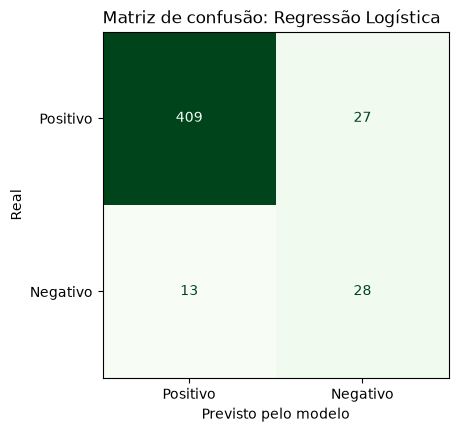

In [44]:
model_lr = LogisticRegression(max_iter=2000)

t0 = time.time()
model_lr.fit(X_train_balanced_t, y_train_balanced)   # treino BALANCEADO
print(f'Regressão Logística treinado em {time.time() - t0:.1f}s\n')

# Avaliação na VALIDAÇÃO (dados NÃO balanceados); o AUC de treino usa o treino original, sem cópias
metricas_lr, proba_lr = relatorio_validacao('Regressão Logística', model_lr, X_train_t, y_train, X_val_t, y_val)

📌 **Nota**
- 🔎 A Regressão Logística encontra **28 dos 41** negativos (**recall de 68,3%**), com precisão de **50,9%** e **F1 de 58,3%**.
- 🔎 **AUC-ROC de 0,944**, o maior entre os algoritmos com o limiar padrão, e PR-AUC de **0,587**.
- ✅ **Menor sobreajuste:** a diferença entre treino e validação é de só **0,05** no AUC. Um modelo linear, com um peso por palavra, generaliza melhor com poucos exemplos e milhares de colunas.

### Naive Bayes

O **Naive Bayes** foi o algoritmo da **versão original**. Ele calcula a probabilidade de cada palavra aparecer em reviews positivos e negativos e combina essas probabilidades, supondo que as palavras são independentes.

Naive Bayes treinado em 0.0s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.150,0
1,0,0.270,0
2,0,0.009,0
3,0,0.288,0
4,0,0.156,0
5,0,0.012,0
6,0,0.279,0
7,0,0.032,0


MÉTRICAS DE VALIDAÇÃO: Naive Bayes
Acurácia                 0.8994
Precisão                 0.4533
Recall (Sensibilidade)   0.8293
F1-Score                 0.5862
AUC-ROC                  0.9356
PR-AUC                   0.6398
                         (sorteio: PR-AUC = 0.0860, AUC-ROC = 0,50)

AUC-ROC no treino: 0.9946 | na validação: 0.9356 | diferença: +0.0590

              precision    recall  f1-score   support

Positivo (0)     0.9826    0.9060    0.9427       436
Negativo (1)     0.4533    0.8293    0.5862        41

    accuracy                         0.8994       477
   macro avg     0.7180    0.8676    0.7645       477
weighted avg     0.9371    0.8994    0.9121       477



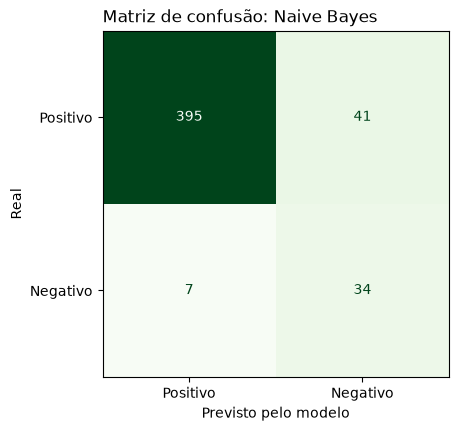

In [45]:
model_nb = MultinomialNB()

t0 = time.time()
model_nb.fit(X_train_balanced_t, y_train_balanced)   # treino BALANCEADO
print(f'Naive Bayes treinado em {time.time() - t0:.1f}s\n')

# Avaliação na VALIDAÇÃO (dados NÃO balanceados); o AUC de treino usa o treino original, sem cópias
metricas_nb, proba_nb = relatorio_validacao('Naive Bayes', model_nb, X_train_t, y_train, X_val_t, y_val)

📌 **Nota**
- 🔎 O Naive Bayes (algoritmo da versão original) tem o **maior recall (82,9%)**: encontra **34 dos 41** negativos. O preço é a precisão de **45,3%**, com 41 alarmes falsos.
- 🔎 É o **melhor na validação** pela PR-AUC (**0,640**) e pelo F1 (**58,6%**), praticamente empatado com a Regressão Logística.
- ⚠️ Como a validação tem só 41 negativos, a validação cruzada a seguir mostra se essa vantagem se mantém.

### Validação cruzada (complemento)

A validação tem só **41 reviews negativos**: um ou dois acertos a mais mudam bastante as métricas. Para saber se as diferenças entre os algoritmos são **reais**, repetimos a comparação com **validação cruzada de 5 partes** em treino + validação (cada parte faz o papel de validação uma vez). O resultado é a **média ± desvio** da PR-AUC: quanto menor o desvio, mais **estável** o algoritmo.

In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
construtores = {'XGBoost': model_xgb, 'Random Forest': model_rf, 'LightGBM': model_lgbm,
                'Regressão Logística': model_lr, 'Naive Bayes': model_nb}

resultados_cv = {}
for nome, modelo in construtores.items():
    pipeline = Pipeline([('prep', criar_preprocessador()), ('smote', SMOTE(random_state=SEED)), ('modelo', clone(modelo))])
    r = cross_validate(pipeline, X_temp, y_temp, cv=cv, scoring=['average_precision', 'f1', 'recall'], n_jobs=-1)
    resultados_cv[nome] = {'PR-AUC (média)': r['test_average_precision'].mean(),
                           'PR-AUC (desvio)': r['test_average_precision'].std(),
                           'F1 (média)': r['test_f1'].mean(), 'Recall (média)': r['test_recall'].mean()}

tabela_cv = pd.DataFrame(resultados_cv).T.sort_values('PR-AUC (média)', ascending=False)
tabela_cv.round(3)

,PR-AUC (média),PR-AUC (desvio),F1 (média),Recall (média)
Regressão Logística,0.569,0.038,0.566,0.640
Naive Bayes,0.550,0.078,0.499,0.744
LightGBM,0.518,0.056,0.456,0.384
XGBoost,0.491,0.066,0.411,0.366
Random Forest,0.453,0.067,0.315,0.219


📌 **Nota**
- 🔎 Na validação cruzada, a **Regressão Logística** tem a **maior PR-AUC média (0,569)** e o **menor desvio (0,038)**: é o algoritmo mais **estável**.
- 🔎 O **Naive Bayes**, que liderou na validação, fica em 2º (**0,550**) com o **maior desvio (0,078)**: o resultado dele varia muito conforme os reviews de cada parte. A vantagem na validação foi, em boa parte, **sorte da divisão**.
- 🔎 Os três modelos de árvore ficam atrás (de 0,453 a 0,518), confirmando a validação.

## 6 - Comparação do desempenho dos modelos

Agora os algoritmos são colocados lado a lado, com as mesmas métricas, na mesma **validação**. Entram duas métricas novas:

| Métrica | Pergunta que ela responde |
|---|---|
| **Especificidade** | De todos os reviews **positivos**, quantos o modelo reconheceu como positivos? |
| **Valor Preditivo Negativo (VPN)** | Quando o modelo diz "**positivo**", quantas vezes ele acerta? |

In [47]:
metricas_validacao = {'XGBoost': metricas_xgb, 'Random Forest': metricas_rf, 'LightGBM': metricas_lgbm,
                      'Regressão Logística': metricas_lr, 'Naive Bayes': metricas_nb}

df_comparacao = pd.DataFrame(metricas_validacao).T
df_comparacao['PR-AUC CV (média ± desvio)'] = [f"{tabela_cv.loc[m, 'PR-AUC (média)']:.3f} ± {tabela_cv.loc[m, 'PR-AUC (desvio)']:.3f}"
                                               for m in df_comparacao.index]
df_comparacao = df_comparacao.sort_values('PR-AUC', ascending=False)
df_comparacao.to_csv('../reports/comparacao_modelos.csv')

colunas_pct = ['Acurácia', 'Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'Especificidade', 'Valor Preditivo Negativo']
df_comparacao.drop(columns=['AUC-ROC treino']).style.format({**{c: '{:.1%}' for c in colunas_pct},
                                                             'AUC-ROC': '{:.3f}', 'PR-AUC': '{:.3f}'}) \
    .highlight_max(subset=['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC'], color='#d4edda')

,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,AUC-ROC,PR-AUC,Especificidade,Valor Preditivo Negativo,Verdadeiros Positivos,Verdadeiros Negativos,Falsos Positivos,Falsos Negativos,PR-AUC CV (média ± desvio)
Naive Bayes,89.9%,45.3%,82.9%,58.6%,0.936,0.640,90.6%,98.3%,34.000000,395.000000,41.000000,7.000000,0.550 ± 0.078
Regressão Logística,91.6%,50.9%,68.3%,58.3%,0.944,0.587,93.8%,96.9%,28.000000,409.000000,27.000000,13.000000,0.569 ± 0.038
LightGBM,92.7%,61.5%,39.0%,47.8%,0.909,0.545,97.7%,94.5%,16.000000,426.000000,10.000000,25.000000,0.518 ± 0.056
XGBoost,90.8%,44.8%,31.7%,37.1%,0.874,0.418,96.3%,93.8%,13.000000,420.000000,16.000000,28.000000,0.491 ± 0.066
Random Forest,90.8%,41.2%,17.1%,24.1%,0.907,0.405,97.7%,92.6%,7.000000,426.000000,10.000000,34.000000,0.453 ± 0.067


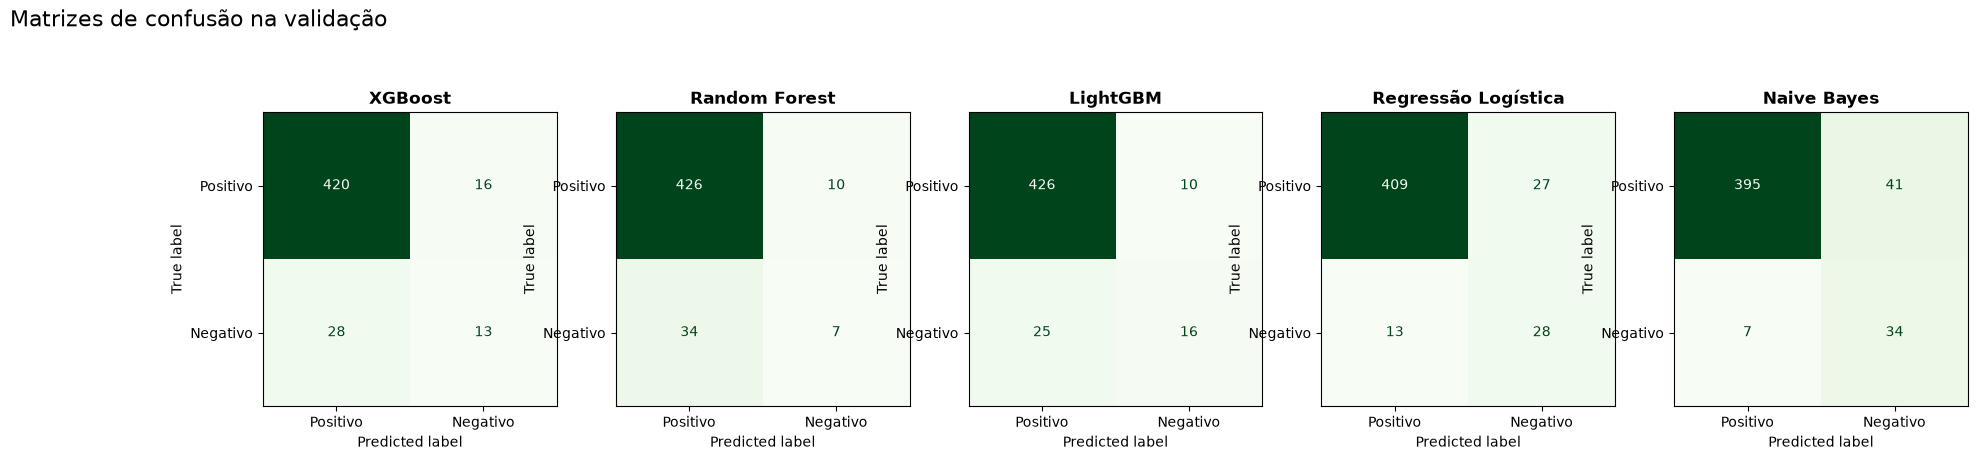

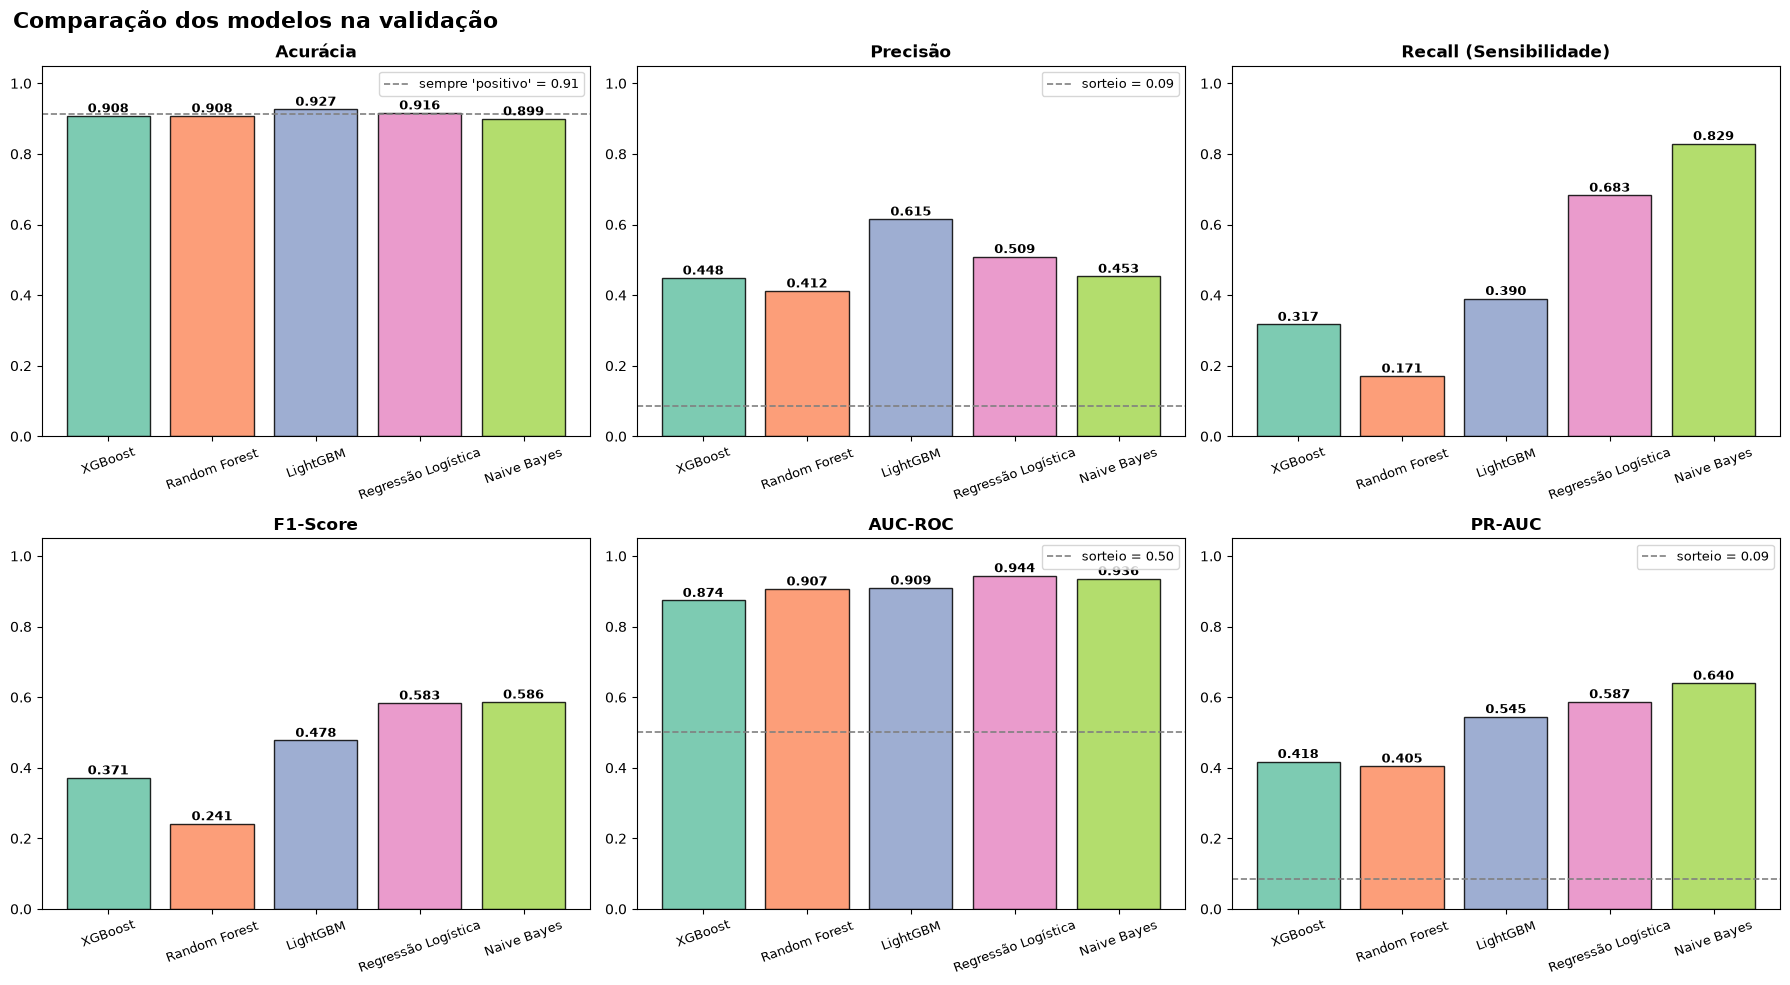

In [48]:
# Matrizes de confusão lado a lado (limiar 0,5)
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (nome, proba) in zip(axes, [('XGBoost', proba_xgb), ('Random Forest', proba_rf), ('LightGBM', proba_lgbm),
                                    ('Regressão Logística', proba_lr), ('Naive Bayes', proba_nb)]):
    ConfusionMatrixDisplay.from_predictions(y_val, (proba >= 0.5).astype(int), display_labels=['Positivo', 'Negativo'],
                                            cmap='Greens', colorbar=False, ax=ax)
    ax.set_title(nome, fontweight='bold')
plt.suptitle('Matrizes de confusão na validação', fontsize=16, x=0.01, ha='left', y=1.05)
salvar('Matrizes de confusao comparativas')
plt.show()

plot_comparacao_modelos(metricas_validacao, y_val.mean(), 'Comparacao de modelos')

In [49]:
# Score geral: média de F1, AUC-ROC, Recall e Precisão na validação
score_geral = df_comparacao[['F1-Score', 'AUC-ROC', 'Recall (Sensibilidade)', 'Precisão']].mean(axis=1)
print('📊 SCORE GERAL (média de F1, AUC-ROC, Recall e Precisão):')
for nome, valor in score_geral.sort_values(ascending=False).items():
    print(f'• {nome:<22} {valor:.4f} | PR-AUC CV {df_comparacao.loc[nome, "PR-AUC CV (média ± desvio)"]}')
print('\n💾 Resultados salvos em: reports/comparacao_modelos.csv')

📊 SCORE GERAL (média de F1, AUC-ROC, Recall e Precisão):
• Naive Bayes            0.7011 | PR-AUC CV 0.550 ± 0.078
• Regressão Logística    0.6799 | PR-AUC CV 0.569 ± 0.038
• LightGBM               0.5981 | PR-AUC CV 0.518 ± 0.056
• XGBoost                0.5027 | PR-AUC CV 0.491 ± 0.066
• Random Forest          0.4326 | PR-AUC CV 0.453 ± 0.067

💾 Resultados salvos em: reports/comparacao_modelos.csv


📌 **Nota**
- 🔎 **Como ler o painel:** cada gráfico é uma métrica, com uma barra por modelo. A **linha tracejada** é a régua de um "modelo que chuta": acertar 91% dizendo sempre "positivo", precisão e PR-AUC de 0,086 sorteando e AUC de 0,50.
- 🔎 **Acurácia:** todas as barras ficam **perto da linha de 91%**. É a prova visual de que a acurácia **não serve** para escolher o modelo aqui.
- 🔎 **Recall:** é onde os modelos mais se diferenciam: Naive Bayes (**82,9%**) e Regressão Logística (**68,3%**) contra 17% a 39% dos modelos de árvore.
- 🔎 **Score geral** (média de F1, AUC-ROC, recall e precisão na validação): Naive Bayes **0,701**, Regressão Logística **0,680**, LightGBM 0,598.
- ✅ **Escolha: Regressão Logística.** Está praticamente empatada com o Naive Bayes na validação, mas é a **melhor e mais estável** na validação cruzada (0,569 ± 0,038), tem o **menor sobreajuste**, gera probabilidades para ajustar o limiar e tem **pesos interpretáveis por palavra**, que o app usa para explicar cada decisão.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

Ajustamos a **Regressão Logística** com uma busca aleatória (`RandomizedSearchCV`, 30 combinações × 5 partes da validação cruzada **dentro do treino**). O pré-processador fica dentro de um `Pipeline` e é **reajustado em cada parte**, sem vazamento. No lugar do SMOTE, usamos `class_weight='balanced'`: o treino fica **sem cópias** e o desbalanceamento é compensado pelo peso dos erros.

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `C` | Força da regularização: valores baixos deixam o modelo mais "conservador", altos dão mais liberdade às palavras | 0,01 a 100 |
| `ngram_range` | Usar só palavras isoladas ou também pares (*"not working"*) | (1, 1) ou (1, 2) |
| `min_df` | Mínimo de reviews em que a palavra precisa aparecer | 1, 2 ou 3 |

A busca otimiza a **PR-AUC**, que mede a qualidade do modelo independentemente do limiar (o limiar é escolhido depois, no item 8).

### 7.1. Random Search

busca concluída em 15s

Melhores hiperparâmetros: {'modelo__C': np.float64(8.471801418819979), 'prep__texto__min_df': 1, 'prep__texto__ngram_range': (1, 1)}
PR-AUC (validação cruzada no treino): 0.571


,rank_test_score,mean_test_score,std_test_score,param_modelo__C,param_prep__texto__ngram_range,param_prep__texto__min_df
1,1,0.571,0.072,8.472,"(1, 1)",1
28,2,0.568,0.075,1.441,"(1, 1)",2
24,3,0.559,0.065,37.959,"(1, 1)",2
25,4,0.558,0.067,48.696,"(1, 1)",2
27,5,0.558,0.079,23.886,"(1, 2)",1


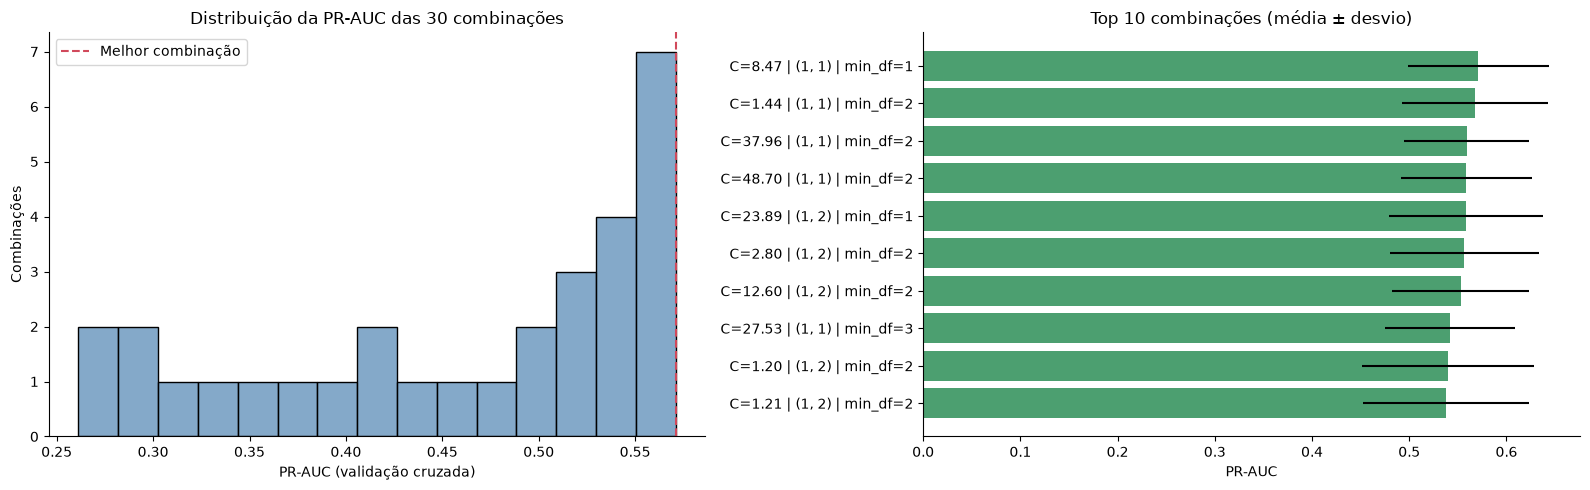

In [50]:
pipeline_lr = Pipeline([('prep', criar_preprocessador()),
                        ('modelo', LogisticRegression(max_iter=2000, class_weight='balanced'))])
espaco_busca = {
    'modelo__C': loguniform(0.01, 100),
    'prep__texto__ngram_range': [(1, 1), (1, 2)],
    'prep__texto__min_df': [1, 2, 3],
}

busca = RandomizedSearchCV(pipeline_lr, espaco_busca, n_iter=30, scoring='average_precision', cv=cv,
                           random_state=SEED, n_jobs=-1)
t0 = time.time()
busca.fit(X_train, y_train)   # treino ORIGINAL (sem cópias)
print(f'busca concluída em {time.time() - t0:.0f}s')

resultados_busca = pd.DataFrame(busca.cv_results_)
top5 = (resultados_busca.sort_values('rank_test_score')
        [['rank_test_score', 'mean_test_score', 'std_test_score', 'param_modelo__C',
          'param_prep__texto__ngram_range', 'param_prep__texto__min_df']].head(5))
print(f'\nMelhores hiperparâmetros: {busca.best_params_}')
print(f'PR-AUC (validação cruzada no treino): {busca.best_score_:.3f}')
display(top5.round(3))

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(resultados_busca['mean_test_score'], bins=15, color='#5B8DB8', ax=axs[0])
axs[0].axvline(busca.best_score_, color='#D1495B', ls='--', label='Melhor combinação')
axs[0].set(title='Distribuição da PR-AUC das 30 combinações', xlabel='PR-AUC (validação cruzada)', ylabel='Combinações')
axs[0].legend()
top10 = resultados_busca.sort_values('rank_test_score').head(10)
axs[1].barh([f'C={c:.2f} | {n} | min_df={d}' for c, n, d in zip(top10['param_modelo__C'], top10['param_prep__texto__ngram_range'],
                                                                 top10['param_prep__texto__min_df'])][::-1],
            top10['mean_test_score'][::-1], xerr=top10['std_test_score'][::-1], color='#4C9F70')
axs[1].set(title='Top 10 combinações (média ± desvio)', xlabel='PR-AUC')
sns.despine()
plt.tight_layout()
salvar('Random Search')
plt.show()

📌 **Nota**
- 🔎 Melhor combinação: `C ≈ 8,5` (menos regularização, dando mais peso às palavras), **só palavras isoladas** (`ngram_range=(1, 1)`) e `min_df=1`, com PR-AUC de **0,571** na validação cruzada do treino.
- 🔎 As 5 melhores combinações ficam entre **0,558 e 0,571**, com desvio de ~0,07: várias configurações funcionam quase igual, o que indica um modelo **robusto** às escolhas.
- 💡 Os pares de palavras (*"not working"*) não ajudaram: como as negações foram **mantidas** no texto, a palavra *not* sozinha já carrega a informação de negação.

### 7.2. Regressão Logística ajustada

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade,Previsão da máquina
0,0,0.022,0
1,0,0.192,0
2,0,0.009,0
3,0,0.284,0
4,0,0.025,0
5,0,0.004,0
6,0,0.026,0
7,0,0.006,0


MÉTRICAS DE VALIDAÇÃO: Regressão Logística ajustada
Acurácia                 0.9161
Precisão                 0.5111
Recall (Sensibilidade)   0.5610
F1-Score                 0.5349
AUC-ROC                  0.9520
PR-AUC                   0.6471
                         (sorteio: PR-AUC = 0.0860, AUC-ROC = 0,50)



AUC-ROC no treino: 1.0000 | na validação: 0.9520 | diferença: +0.0480

              precision    recall  f1-score   support

Positivo (0)     0.9583    0.9495    0.9539       436
Negativo (1)     0.5111    0.5610    0.5349        41

    accuracy                         0.9161       477
   macro avg     0.7347    0.7553    0.7444       477
weighted avg     0.9199    0.9161    0.9179       477



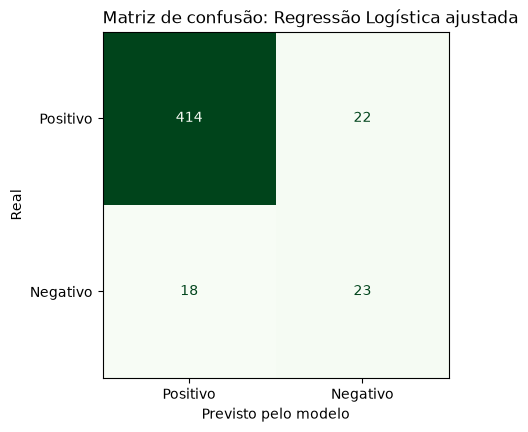

,Precisão,Recall (Sensibilidade),F1-Score,AUC-ROC,PR-AUC
"Regressão Logística (SMOTE, padrão)",0.509,0.683,0.583,0.944,0.587
Regressão Logística ajustada,0.511,0.561,0.535,0.952,0.647


In [51]:
# Avaliar o melhor modelo na VALIDAÇÃO (o Pipeline recebe o review cru)
modelo_ajustado = busca.best_estimator_
metricas_ajustado, proba_ajustado = relatorio_validacao('Regressão Logística ajustada', modelo_ajustado,
                                                         X_train, y_train, X_val, y_val)

comparacao_ajuste = pd.DataFrame({'Regressão Logística (SMOTE, padrão)': metricas_lr,
                                  'Regressão Logística ajustada': metricas_ajustado}).T
comparacao_ajuste[['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC']].round(3)

📌 **Nota**
- 🔎 Na validação, o ajuste elevou a **PR-AUC de 0,587 para 0,647** (+10%) e o AUC-ROC de 0,944 para **0,952**: o modelo ajustado **ordena melhor** os reviews.
- 🔎 Com o limiar de 0,50, o recall caiu (68,3% → 56,1%) porque o `class_weight` gera probabilidades diferentes das do SMOTE. Isso é resolvido no **item 8**, com a escolha do limiar.

### 7.3. Modelo final

O modelo final é uma **cópia "zerada"** (`clone`) do melhor Pipeline, com os mesmos hiperparâmetros, treinada em **treino + validação** (80% dos dados, sem cópias). Ele é avaliado no **teste** pela primeira e única vez.

In [52]:
modelo_final = clone(busca.best_estimator_)
modelo_final.fit(X_temp, y_temp)   # treino + validação

prob_teste = modelo_final.predict_proba(X_test)[:, 1]
metricas_teste_05 = calcular_metricas_completas(y_test, (prob_teste >= 0.5).astype(int), prob_teste)

pd.DataFrame({'Validação (modelo ajustado)': metricas_ajustado, 'Teste (modelo final)': metricas_teste_05}).loc[
    ['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC']].round(3)

,Validação (modelo ajustado),Teste (modelo final)
Precisão,0.511,0.639
Recall (Sensibilidade),0.561,0.561
F1-Score,0.535,0.597
AUC-ROC,0.952,0.924
PR-AUC,0.647,0.595


📌 **Nota**
- 🔎 No teste, com o limiar de 0,50: **PR-AUC de 0,595** e **AUC-ROC de 0,924**, um pouco abaixo da validação (0,647 e 0,952). A queda é pequena e esperada: o teste tem só 41 negativos, e a validação foi usada para escolher o modelo.
- 🔎 O recall é o mesmo (**56,1%**) e a precisão sobe para **63,9%**. Não há sinal de que o modelo tenha "decorado" a validação.

## 8 - Otimização de limiar e calibração

### 8.1. Convertendo probabilidades em 0 ou 1

O modelo não diz apenas "negativo" ou "positivo": ele calcula uma **probabilidade** (um score de 0 a 1). O **limiar** é o ponto de corte: acima dele, o review é classificado como negativo. O padrão é **0,5**, mas não precisa ser.

| Limiar | Efeito |
|---|---|
| **Mais baixo** | Marca mais reviews como negativos → encontra mais clientes insatisfeitos (**recall ↑**), com mais alarmes falsos (**precisão ↓**) |
| **Mais alto** | Marca menos reviews → menos alarmes falsos (**precisão ↑**), mas deixa passar mais clientes insatisfeitos (**recall ↓**) |

In [53]:
# O mesmo modelo, com limiares diferentes, na VALIDAÇÃO
linhas = []
for corte in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    previsto = (proba_ajustado >= corte).astype(int)
    linhas.append({'Limiar': corte, 'Reviews marcados': previsto.sum(),
                   'Negativos encontrados': ((previsto == 1) & (y_val == 1)).sum(),
                   'Alarmes falsos': ((previsto == 1) & (y_val == 0)).sum(),
                   'Precisão': precision_score(y_val, previsto, zero_division=0), 'Recall': recall_score(y_val, previsto)})
pd.DataFrame(linhas).set_index('Limiar').round(3)

,Reviews marcados,Negativos encontrados,Alarmes falsos,Precisão,Recall
Limiar,,,,,
0.2,112,41,71,0.366,1.000
0.3,83,36,47,0.434,0.878
0.4,63,31,32,0.492,0.756
0.5,45,23,22,0.511,0.561
0.6,34,19,15,0.559,0.463
0.7,25,15,10,0.600,0.366


### 8.2. Escolhendo o limiar

Comparamos **três critérios** na validação (o teste continua guardado):

| Critério | Como funciona |
|---|---|
| **F1 máximo** | o limiar que melhor equilibra precisão e recall (`limiar_otimo_f1`) |
| **Custo mínimo** | deixar um cliente insatisfeito sem resposta (**falso negativo**) custa **5 vezes** mais que ler um review positivo à toa (**falso positivo**) |
| **Meta de recall** | o maior limiar que encontra pelo menos **75%** dos negativos |

,Limiar,Precisão,Recall,F1,Custo
"Padrão (0,50)",0.500,0.511,0.561,0.535,112.0
F1 máximo,0.405,0.500,0.756,0.602,81.0
Custo mínimo (FN = 5 × FP),0.250,0.415,0.951,0.578,65.0
Meta de recall (75%),0.405,0.500,0.756,0.602,81.0


Limiar escolhido: 0.405


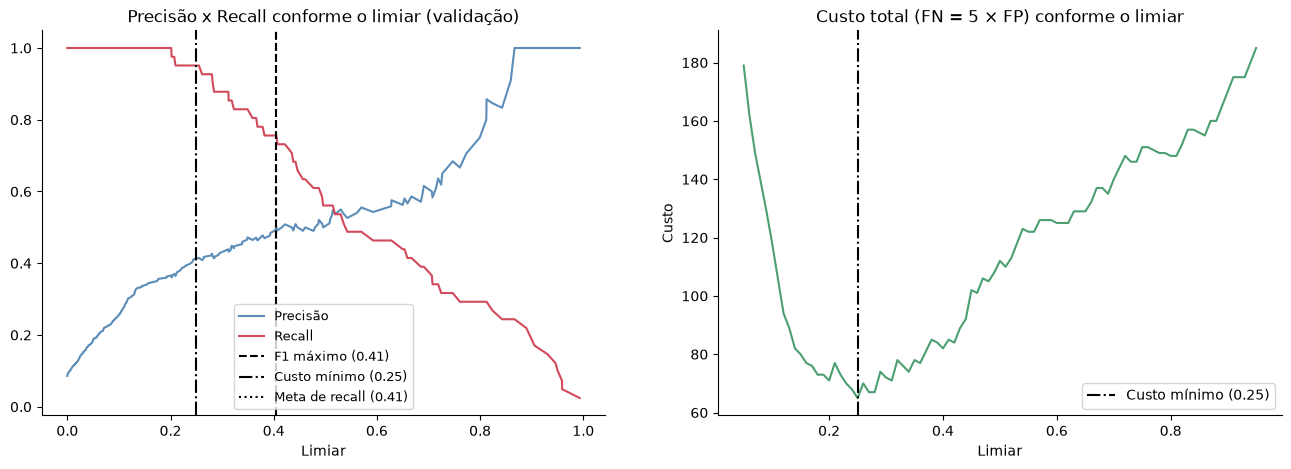

In [54]:
limiar_f1, f1_max = limiar_otimo_f1(y_val, proba_ajustado)

custos = curva_custo(y_val, proba_ajustado, custo_fn=5, custo_fp=1)
limiar_custo = float(custos.loc[custos['Custo'].idxmin(), 'Limiar'])

precisao, recall, limiares = precision_recall_curve(y_val, proba_ajustado)
META_RECALL = 0.75
limiar_meta = float(limiares[recall[:-1] >= META_RECALL].max())

resumo_limiares = {}
for nome, corte in [('Padrão (0,50)', 0.5), ('F1 máximo', limiar_f1), ('Custo mínimo (FN = 5 × FP)', limiar_custo),
                    (f'Meta de recall ({META_RECALL:.0%})', limiar_meta)]:
    previsto = (proba_ajustado >= corte).astype(int)
    resumo_limiares[nome] = {'Limiar': corte, 'Precisão': precision_score(y_val, previsto, zero_division=0),
                             'Recall': recall_score(y_val, previsto), 'F1': f1_score(y_val, previsto),
                             'Custo': 5 * ((previsto == 0) & (y_val == 1)).sum() + ((previsto == 1) & (y_val == 0)).sum()}
display(pd.DataFrame(resumo_limiares).T.round(3))

# Decisão de negócio: encontrar pelo menos 75% dos clientes insatisfeitos (ver nota abaixo)
limiar = limiar_meta
print(f'Limiar escolhido: {limiar:.3f}')

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
axs[0].plot(limiares, precisao[:-1], label='Precisão', color='#5B8DB8')
axs[0].plot(limiares, recall[:-1], label='Recall', color='#D1495B')
for nome, corte, estilo in [('F1 máximo', limiar_f1, '--'), ('Custo mínimo', limiar_custo, '-.'), ('Meta de recall', limiar_meta, ':')]:
    axs[0].axvline(corte, color='black', ls=estilo, label=f'{nome} ({corte:.2f})')
axs[0].set(title='Precisão x Recall conforme o limiar (validação)', xlabel='Limiar')
axs[0].legend(fontsize=9)
axs[1].plot(custos['Limiar'], custos['Custo'], color='#4C9F70')
axs[1].axvline(limiar_custo, color='black', ls='-.', label=f'Custo mínimo ({limiar_custo:.2f})')
axs[1].set(title='Custo total (FN = 5 × FP) conforme o limiar', xlabel='Limiar', ylabel='Custo')
axs[1].legend()
sns.despine()
salvar('Escolha do limiar')
plt.show()

📌 **Nota**
- 🔎 O **F1 máximo** e a **meta de recall de 75%** apontam para o **mesmo limiar (0,405)**: encontra **75,6%** dos negativos da validação, com precisão de **50%**.
- 🔎 O **custo mínimo** (perder um cliente insatisfeito custa 5 vezes mais que ler um review à toa) aponta para **0,25**: recall de **95%**, mas precisão de 41,5% (mais reviews para ler).
- ✅ **Decisão: limiar de 0,405.** Atende à meta de encontrar 3 em cada 4 clientes insatisfeitos com metade dos alertas corretos. O limiar de 0,25 fica como **alternativa** para quando o time tiver mais capacidade de leitura.

### 8.3. Aplicando o limiar escolhido no teste

Agora, pela **primeira e única vez**, usamos o teste com o limiar escolhido na validação. Para mostrar o valor do modelo em linguagem de negócio, comparamos com um **sorteio**: se o time lesse o mesmo número de reviews escolhidos ao acaso, quantos negativos encontraria?

In [55]:
previsto_teste = (prob_teste >= limiar).astype(int)

linhas = {}
for nome, corte in [('Limiar padrão (0,50)', 0.5), (f'Limiar escolhido ({limiar:.2f})', limiar)]:
    previsto = (prob_teste >= corte).astype(int)
    linhas[nome] = {'Precisão': precision_score(y_test, previsto), 'Recall': recall_score(y_test, previsto),
                    'F1': f1_score(y_test, previsto),
                    'Negativos encontrados': f'{((previsto == 1) & (y_test == 1)).sum()} de {y_test.sum()}',
                    'Alarmes falsos': ((previsto == 1) & (y_test == 0)).sum()}
display(pd.DataFrame(linhas).T)

lidos = previsto_teste.sum()
print(f'Lendo {lidos} reviews marcados pelo modelo: {((previsto_teste == 1) & (y_test == 1)).sum()} negativos encontrados.')
print(f'Lendo {lidos} reviews sorteados: {lidos * y_test.mean():.1f} negativos encontrados, em média.')

,Precisão,Recall,F1,Negativos encontrados,Alarmes falsos
"Limiar padrão (0,50)",0.638889,0.560976,0.597403,23 de 41,13
Limiar escolhido (0.41),0.6,0.658537,0.627907,27 de 41,18


Lendo 45 reviews marcados pelo modelo: 27 negativos encontrados.
Lendo 45 reviews sorteados: 3.9 negativos encontrados, em média.


📌 **Nota**

| | Limiar 0,50 | Limiar 0,405 |
|---|---|---|
| Negativos encontrados | 23 de 41 (56%) | **27 de 41 (66%)** |
| Alarmes falsos | 13 | 18 |
| F1 | 59,7% | **62,8%** |

- 🔎 O limiar escolhido encontra **4 clientes insatisfeitos a mais**, ao custo de **5 reviews extras** para o time ler. No total, o modelo sinaliza **45 dos 477 reviews (9,4%)**.
- 🔎 **Contra um sorteio:** lendo os mesmos 45 reviews escolhidos ao acaso, o time encontraria em média **3,9 negativos**. O modelo encontra **27, quase 7 vezes mais**.
- 🔎 O recall no teste (66%) ficou abaixo dos 75,6% da validação: com 41 negativos, cada review vale 2,4 pontos percentuais, então a diferença são **4 reviews**.

### 8.4. Calibração (versão simples)

Uma probabilidade é **calibrada** quando ela "significa o que diz": entre os reviews com score de 30%, cerca de 30% deveriam ser negativos. Como usamos `class_weight='balanced'`, o modelo tende a **superestimar** a probabilidade de negativo. Agrupamos os reviews do teste por faixa de probabilidade e comparamos a probabilidade média com a proporção real de negativos.

,probabilidade_media,proporcao_real,reviews
faixa,,,
"(-0.00099412, 0.00198]",0.001,0.000,60
"(0.00198, 0.00938]",0.006,0.000,60
"(0.00938, 0.0193]",0.014,0.000,59
"(0.0193, 0.0361]",0.027,0.017,60
"(0.0361, 0.0712]",0.049,0.000,59
"(0.0712, 0.134]",0.100,0.083,60
"(0.134, 0.32]",0.198,0.085,59
"(0.32, 0.993]",0.608,0.500,60


Brier score (erro médio das probabilidades, menor é melhor): 0.0534


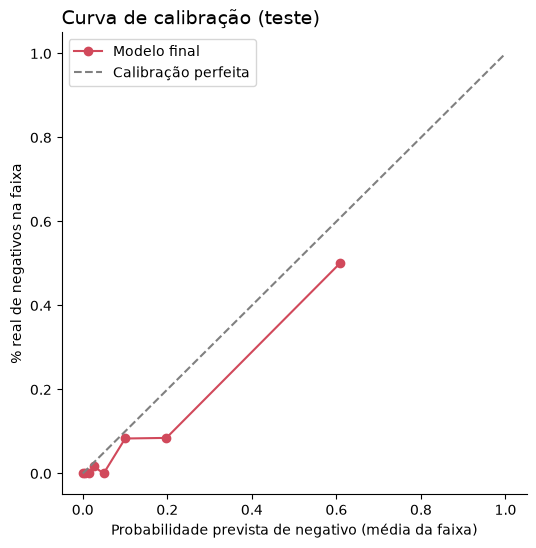

In [56]:
faixas = pd.qcut(prob_teste, q=8, duplicates='drop')
calibracao = (pd.DataFrame({'probabilidade': prob_teste, 'real': y_test.values, 'faixa': faixas})
              .groupby('faixa', observed=True).agg(probabilidade_media=('probabilidade', 'mean'),
                                                   proporcao_real=('real', 'mean'), reviews=('real', 'size')))
display(calibracao.round(3))
print(f'Brier score (erro médio das probabilidades, menor é melhor): {brier_score_loss(y_test, prob_teste):.4f}')

plt.figure(figsize=(6, 6))
plt.plot(calibracao['probabilidade_media'], calibracao['proporcao_real'], marker='o', color='#D1495B', label='Modelo final')
plt.plot([0, 1], [0, 1], ls='--', color='grey', label='Calibração perfeita')
plt.xlabel('Probabilidade prevista de negativo (média da faixa)')
plt.ylabel('% real de negativos na faixa')
plt.title('Curva de calibração (teste)', fontsize=14, loc='left')
plt.legend()
sns.despine()
salvar('Curva de calibracao')
plt.show()

📌 **Nota**
- 🔎 O modelo **superestima** o risco: na faixa de maior probabilidade (média de **61%**), só **50%** são negativos; na faixa de ~20%, só **8,5%** são negativos. É o efeito do `class_weight='balanced'`.
- 🔎 Brier score de **0,053** (erro médio das probabilidades).
- ✅ **Decisão:** manter o modelo sem recalibração. O que importa para o time é a **ordem** de prioridade (quem ler primeiro) e o limiar, que já foi escolhido sobre esses scores. Por isso, no app o valor é apresentado como **"score de negatividade"**, e não como uma probabilidade exata.

## 9 - Teste anti-vazamento

Na Fase 02 (item 2.5.2), retiramos a coluna `rating` (a nota do cliente) porque o rótulo foi **criado a partir dela**. Para mostrar o tamanho do problema que isso evita, treinamos o **mesmo modelo** com a nota incluída e comparamos na validação.

> Se a nota entrasse no modelo, ele "acertaria" quase tudo, mas seria **inútil**: em produção, o objetivo é justamente descobrir o sentimento de reviews sem depender de nota (ex.: comentários em redes sociais).

,Modelo legítimo (sem a nota),Modelo com vazamento (com a nota)
Precisão,0.511,1.0
Recall (Sensibilidade),0.561,1.0
F1-Score,0.535,1.0
PR-AUC,0.647,1.0


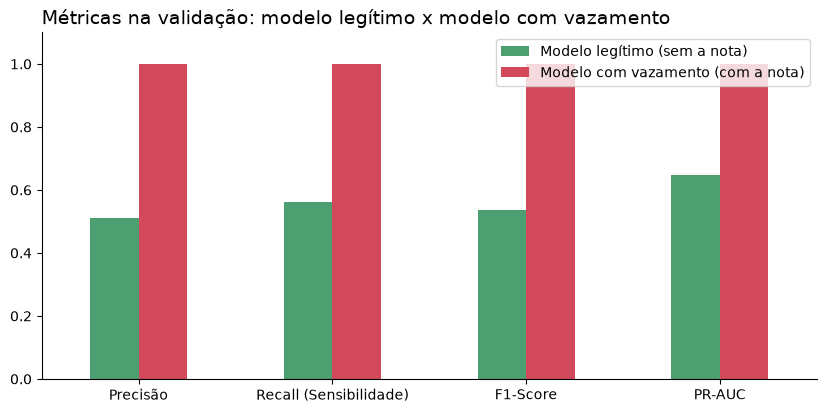

In [57]:
# Reintroduzindo 'rating' para evidenciar por que ela foi excluída
def preprocessador_com_vazamento():
    prep = criar_preprocessador(**{k.replace('prep__texto__', ''): v for k, v in busca.best_params_.items()
                                   if k.startswith('prep__')})
    return ColumnTransformer(prep.transformers + [('nota', OneHotEncoder(handle_unknown='ignore'), ['rating'])])

X_train_vaz = X_train.join(df_limpo['rating'])
X_val_vaz = X_val.join(df_limpo['rating'])
modelo_vazamento = Pipeline([('prep', preprocessador_com_vazamento()),
                             ('modelo', clone(busca.best_estimator_.named_steps['modelo']))]).fit(X_train_vaz, y_train)
proba_vaz = modelo_vazamento.predict_proba(X_val_vaz)[:, 1]
metricas_vaz = calcular_metricas_completas(y_val, (proba_vaz >= 0.5).astype(int), proba_vaz)

vazamento = pd.DataFrame({'Modelo legítimo (sem a nota)': metricas_ajustado, 'Modelo com vazamento (com a nota)': metricas_vaz}
                         ).loc[['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'PR-AUC']]
display(vazamento.round(3))

ax = vazamento.plot.bar(figsize=(10, 4.5), rot=0, color=['#4C9F70', '#D1495B'])
ax.set_ylim(0, 1.1)
ax.set_title('Métricas na validação: modelo legítimo x modelo com vazamento', loc='left', fontsize=14)
sns.despine()
salvar('Teste anti-vazamento')
plt.show()

### 🛡️ Resumo: houve vazamento? Foi resolvido?
- 🔎 Com a nota (`rating`) como entrada, o modelo acerta **100%** na validação: precisão, recall, F1 e PR-AUC iguais a **1,0**. Ele aprende a regra "nota 1 ou 2 = negativo" e **ignora o texto**.
- ✅ **Resolvido:** o modelo legítimo usa só o **texto** e a **variação do produto**, informações que existem para qualquer comentário novo, mesmo sem nota. As métricas mais modestas dele (PR-AUC de 0,647) são as **reais**.

# FASE 04: AVALIAÇÃO

Resultado final do modelo no **teste** (reviews que ele nunca viu), usando o limiar escolhido na validação.

## 1 - Avaliando a Máquina Preditiva

,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,AUC-ROC,PR-AUC,Especificidade,Valor Preditivo Negativo,Verdadeiros Positivos,Verdadeiros Negativos,Falsos Positivos,Falsos Negativos
Teste (limiar escolhido),0.932914,0.6,0.658537,0.627907,0.924424,0.59518,0.958716,0.967593,27.0,418.0,18.0,14.0


              precision    recall  f1-score   support

Positivo (0)      0.968     0.959     0.963       436
Negativo (1)      0.600     0.659     0.628        41

    accuracy                          0.933       477
   macro avg      0.784     0.809     0.796       477
weighted avg      0.936     0.933     0.934       477



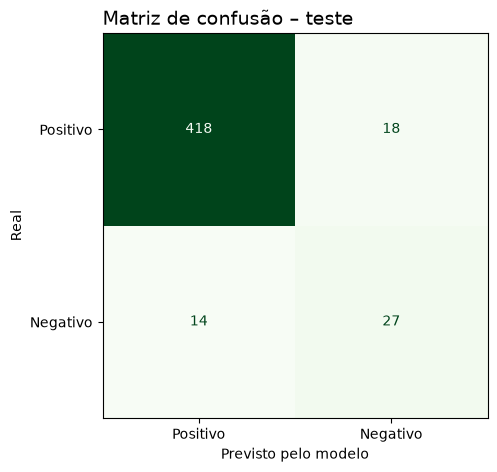

In [58]:
metricas_teste = calcular_metricas_completas(y_test, previsto_teste, prob_teste)
display(pd.Series(metricas_teste).to_frame('Teste (limiar escolhido)').T)

print(classification_report(y_test, previsto_teste, target_names=ROTULOS, digits=3))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, previsto_teste, display_labels=['Positivo', 'Negativo'],
                                        cmap='Greens', colorbar=False, ax=ax)
ax.set(xlabel='Previsto pelo modelo', ylabel='Real')
plt.title('Matriz de confusão – teste', fontsize=14, loc='left')
salvar('Matriz de confusao')
plt.show()

📌 **Nota – resultado final no teste**

| Métrica (classe negativa) | Valor | Em linguagem de negócio |
|---|---|---|
| **Recall** | **65,9%** | De cada **3 clientes insatisfeitos**, o modelo encontra **2** |
| **Precisão** | **60,0%** | De cada **5 alertas**, **3** são realmente reviews negativos |
| **F1** | **62,8%** | Equilíbrio entre os dois |
| **PR-AUC** | **0,595** | ~7x melhor que um sorteio (0,086) |
| **Especificidade** | **95,9%** | Dos reviews positivos, só 4% viram alarme falso |
| **VPN** | **96,8%** | Quando o modelo diz "positivo", acerta 97% das vezes |

- 🔎 A acurácia é de **93,3%**, mas, como visto no item 2.7, ela não é a métrica certa aqui.
- 🔎 **Comparação com a versão original:** o F1 da classe negativa era **43%**, medido numa base com duplicadas, que favorecia o modelo. Agora é **62,8%**, numa avaliação mais rigorosa (sem duplicadas, com validação separada e o teste usado uma única vez).

## 2 - Previsto x observado

Números ajudam, mas em NLP é importante **ler os textos**: onde o modelo acerta e onde ele erra? Também comparamos, por **variação do produto**, a proporção real de reviews negativos com a proporção prevista pelo modelo.

In [59]:
resultado_teste = X_test.assign(real=y_test.values, previsto=previsto_teste, score=prob_teste.round(3))

print('✅ Negativos encontrados (acertos):')
display(resultado_teste.query('real == 1 and previsto == 1').sort_values('score', ascending=False).head(3))
print('❌ Negativos que passaram despercebidos:')
display(resultado_teste.query('real == 1 and previsto == 0').sort_values('score').head(3))
print('⚠️ Alarmes falsos (positivos marcados como negativos):')
display(resultado_teste.query('real == 0 and previsto == 1').sort_values('score', ascending=False).head(3))

✅ Negativos encontrados (acertos):


,verified_reviews,variation,real,previsto,score
988,Can't turn of &#34;things to try&#34; on the screen scroll. This is a big promotion device for Amazon. Packing it up and sending it back. They ...,Black Spot,1,1,0.993
544,product stopped working after return time ran out,Black,1,1,0.980
542,cant seem to get this thing to sink with my wireless not sure If I will be returning it will try one more time.,Black,1,1,0.967


❌ Negativos que passaram despercebidos:


,verified_reviews,variation,real,previsto,score
338,Alexa hardly came on..,Charcoal Fabric,1,0,0.020
1169,Fire HD does so much more. Over priced pair of speakers.,Black Show,1,0,0.072
384,Never could get it to work. A techie friend looked at it for me and said the adapter wasn't strong enough to power it and that it looked like it h...,Black,1,0,0.104


⚠️ Alarmes falsos (positivos marcados como negativos):


,verified_reviews,variation,real,previsto,score
1447,I try use with yale lock but isn’t work,White Plus,0,1,0.940
969,I bought this to replace a Dot in my bedroom. Already have a Show and a couple of full-sized Echo units in my house.The Spot is okay for what it i...,White Spot,0,1,0.899
1682,It appears to be working fine my first Echo stopped replying to my requests and I received the Echo plus very happy no problems no hassel exchange.,Black Plus,0,1,0.871


In [60]:
por_variacao_teste = (resultado_teste.groupby('variation')
                      .agg(reviews=('real', 'size'), negativos_reais=('real', 'sum'), negativos_previstos=('previsto', 'sum'))
                      .query('reviews >= 15').sort_values('negativos_reais', ascending=False))
por_variacao_teste['acertos'] = (resultado_teste.query('real == 1 and previsto == 1').groupby('variation').size()
                                 .reindex(por_variacao_teste.index, fill_value=0))
por_variacao_teste

,reviews,negativos_reais,negativos_previstos,acertos
variation,,,,
Black,51,9,10,7
Black Plus,57,6,5,3
White Show,24,6,5,5
Black Spot,42,6,10,6
Configuration: Fire TV Stick,67,4,3,3
Charcoal Fabric,39,2,0,0
Black Show,54,2,2,1
Black Dot,48,1,5,1
White Dot,26,1,0,0


📌 **Nota**
- 🔎 **Acertos:** textos com sinais claros de problema (*"stopped working"*, *"sending it back"*, *"returning it"*).
- 🔎 **Negativos perdidos:** textos curtos ou indiretos, sem palavras típicas de reclamação (*"Alexa hardly came on.."*, *"Over priced pair of speakers"*). O modelo não entende ironia nem comparações.
- 🔎 **Alarmes falsos:** **7 dos 18** vêm de reviews **nota 3**, que o rótulo considera positivos, mas que contêm críticas (ex.: *"I try use with yale lock but isn't work"*). Ou seja, parte dos "erros" é **limitação do rótulo**, não do modelo.
- 🔎 **Por variação:** o modelo acompanha bem as variações com mais reclamações (Black, White Show, Black Spot), mas **superestima** a Black Dot (5 previstos para 1 real) e não encontra os 2 negativos da Charcoal Fabric.

## 3 - Quais variáveis mais influenciam o modelo?

Olhamos de duas formas:
1. **Importância por permutação** no teste: embaralhamos uma coluna de entrada de cada vez (o **texto** ou a **variação**) e medimos quanto a PR-AUC cai.
2. **Pesos da Regressão Logística**: cada palavra tem um peso. **Positivo** empurra o review para **negativo**; **negativo** empurra para **positivo**.

In [61]:
importancia_perm = permutation_importance(modelo_final, X_test, y_test, scoring='average_precision',
                                          n_repeats=10, random_state=SEED, n_jobs=-1)
pd.DataFrame({'queda média da PR-AUC': importancia_perm.importances_mean,
              'desvio': importancia_perm.importances_std}, index=X_test.columns).round(3)

,queda média da PR-AUC,desvio
verified_reviews,0.488,0.019
variation,0.024,0.023


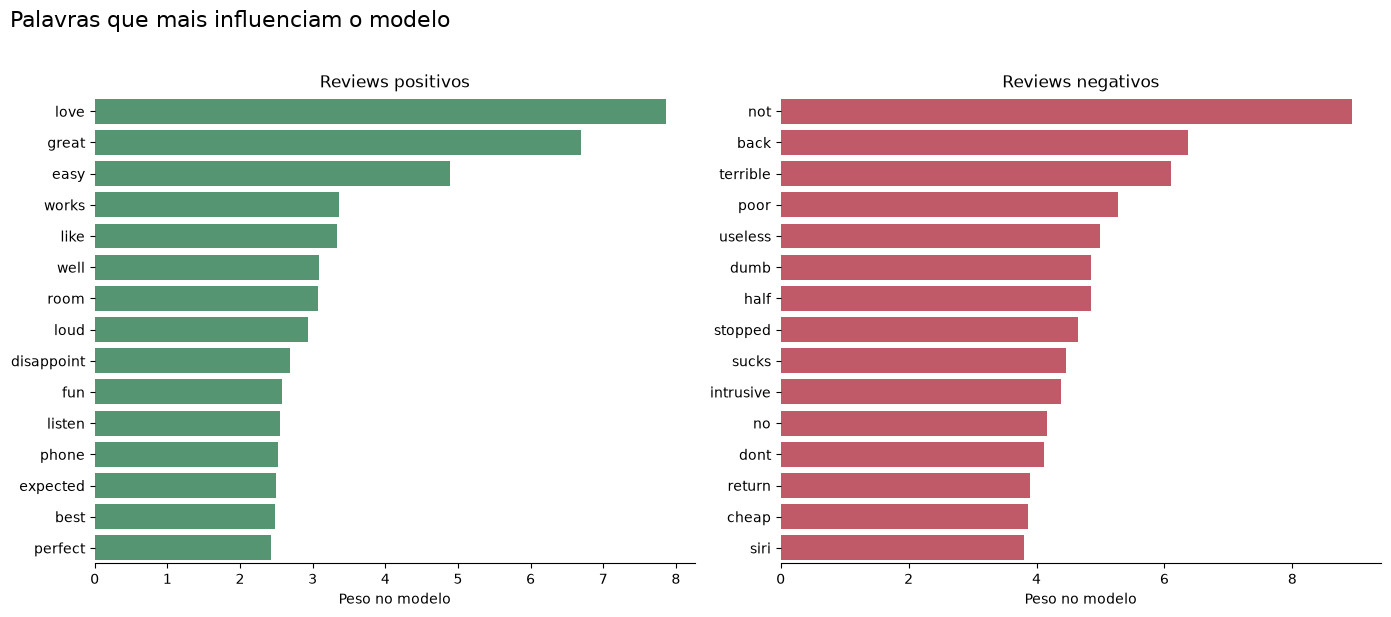

In [62]:
nomes = modelo_final.named_steps['prep'].get_feature_names_out()
pesos = pd.Series(modelo_final.named_steps['modelo'].coef_[0], index=nomes)
pesos_palavras = pesos[pesos.index.str.startswith('texto__')]
pesos_palavras.index = pesos_palavras.index.str.replace('texto__', '')

mais_negativas = pesos_palavras.sort_values(ascending=False).head(15)
mais_positivas = pesos_palavras.sort_values().head(15).abs()

plot_top_palavras(mais_positivas, mais_negativas, 'Palavras que mais influenciam o modelo',
                  'Palavras que mais influenciam o modelo', xlabel='Peso no modelo')

📌 **Nota**
- 🔎 **Importância por permutação:** embaralhar o **texto** derruba a PR-AUC em **0,488**; embaralhar a **variação**, só **0,024**. O modelo depende quase só do que o cliente escreveu (confirma a H4 e a seleção de variáveis).
- 🔎 **Palavras que mais indicam um review negativo:** *not* (a mais forte de todas), *back* e *return* (intenção de **devolver** o produto), *terrible*, *poor*, *useless*, *dumb*, *stopped*, *sucks*, *cheap* e *siri* (clientes **comparando com a concorrência**).
- 🔎 **Palavras que mais indicam um review positivo:** *love*, *great*, *easy*, *works*, *well*, *fun*, *best*, *perfect*.
- ⚠️ *disappoint* aparece do lado **positivo**, enquanto *disappointed* fica do lado negativo: *disappoint* costuma vir negada (*"does not disappoint"*). É uma **limitação** de um modelo que olha palavras isoladas: ele não entende o contexto da frase.
- ✅ **Para o negócio:** reviews com *back*/*return* sinalizam risco de **devolução** e devem ter prioridade no atendimento.

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

O pipeline salvo já contém **tudo**: a limpeza do texto, o TF-IDF, o One-Hot Encoding e a Regressão Logística. Por isso ele recebe o review **cru**. Junto com ele salvamos o **limiar escolhido** e a lista de variações do produto (usada no app).

Salvamos também a **ficha do modelo** (`Model/modelo_sentimento.json`): tudo o que é preciso saber para usá-lo corretamente.

In [63]:
with open('../Model/modelo_sentimento.pkl', 'wb') as arquivo:
    pickle.dump({'pipeline': modelo_final, 'limiar': float(limiar),
                 'variacoes': sorted(df_limpo['variation'].unique())}, arquivo)

ficha = salvar_ficha_modelo(
    '../Model/modelo_sentimento.json',
    modelo='Regressão Logística ajustada (Pipeline: limpeza + TF-IDF + One-Hot + LogisticRegression)',
    arquivo='modelo_sentimento.pkl',
    treinado_com=f'{len(X_temp):,} reviews (treino + validação)'.replace(',', '.'),
    colunas_de_entrada=list(X.columns),
    alvo='negativo (1 = review negativo, nota 1 ou 2)',
    limiar_recomendado=round(float(limiar), 3),
    criterio_do_limiar=f'maior limiar com recall >= {META_RECALL:.0%} na validação',
    metricas_no_teste={k: round(float(v), 4) for k, v in metricas_teste.items()
                       if k in ['Acurácia', 'Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC']},
    hiperparametros={k: str(v) for k, v in busca.best_params_.items()},
    avisos=['Use o score como ORDEM de prioridade de leitura: com class_weight, a probabilidade superestima o risco.',
            "Não use 'rating' como entrada: ela é a origem do rótulo (vazamento).",
            'Treinado com reviews em inglês de produtos Amazon Alexa (2018).'],
)
ficha

{'data_treino': '2026-10-22 17:54',
 'modelo': 'Regressão Logística ajustada (Pipeline: limpeza + TF-IDF + One-Hot + LogisticRegression)',
 'arquivo': 'modelo_sentimento.pkl',
 'treinado_com': '1.907 reviews (treino + validação)',
 'colunas_de_entrada': ['verified_reviews', 'variation'],
 'alvo': 'negativo (1 = review negativo, nota 1 ou 2)',
 'limiar_recomendado': 0.405,
 'criterio_do_limiar': 'maior limiar com recall >= 75% na validação',
 'metricas_no_teste': {'Acurácia': 0.9329,
  'Precisão': 0.6,
  'Recall (Sensibilidade)': 0.6585,
  'F1-Score': 0.6279,
  'AUC-ROC': 0.9244,
  'PR-AUC': 0.5952},
 'hiperparametros': {'modelo__C': '8.471801418819979',
  'prep__texto__min_df': '1',
  'prep__texto__ngram_range': '(1, 1)'},
 'avisos': ['Use o score como ORDEM de prioridade de leitura: com class_weight, a probabilidade superestima o risco.',
  "Não use 'rating' como entrada: ela é a origem do rótulo (vazamento).",
  'Treinado com reviews em inglês de produtos Amazon Alexa (2018).']}

## 2 - Aplicando uma simulação

Testamos três reviews novos, incluindo um com **negação** (*"not worth"*), que a versão original tinha dificuldade em entender.

In [64]:
novos_reviews = pd.DataFrame({
    'verified_reviews': [
        'I love my Echo, the sound is great and Alexa answers everything!',
        'It stopped working after two weeks and customer support did not help.',
        'Not worth the money. The speaker is not loud enough.',
    ],
    'variation': ['Black  Dot', 'Charcoal Fabric ', 'White  Dot'],
})

novos_reviews['score_negativo'] = modelo_final.predict_proba(novos_reviews)[:, 1].round(3)
novos_reviews['sentimento'] = np.where(novos_reviews['score_negativo'] >= limiar, 'Negativo 😞', 'Positivo 😀')
novos_reviews

,verified_reviews,variation,score_negativo,sentimento
0,"I love my Echo, the sound is great and Alexa answers everything!",Black Dot,0.001,Positivo 😀
1,It stopped working after two weeks and customer support did not help.,Charcoal Fabric,0.948,Negativo 😞
2,Not worth the money. The speaker is not loud enough.,White Dot,0.632,Negativo 😞


📌 **Nota**
- ✅ O elogio recebe score de **0,1%**, bem abaixo do limiar → **positivo**.
- ✅ A reclamação de defeito recebe **94,8%** → **negativo**.
- ✅ A frase com negação (*"Not worth the money... not loud enough"*) recebe **63,2%** → **negativo**. Sem manter as negações, palavras como *worth* e *loud* (que pesam para o lado positivo) puxariam o resultado para positivo.

#### Quantos clientes insatisfeitos o time encontra lendo X reviews?

Na prática, o time pode ler os reviews **na ordem do score** (do mais negativo para o menos). Comparamos com ler na ordem em que chegam (equivalente a um **sorteio**), no teste.

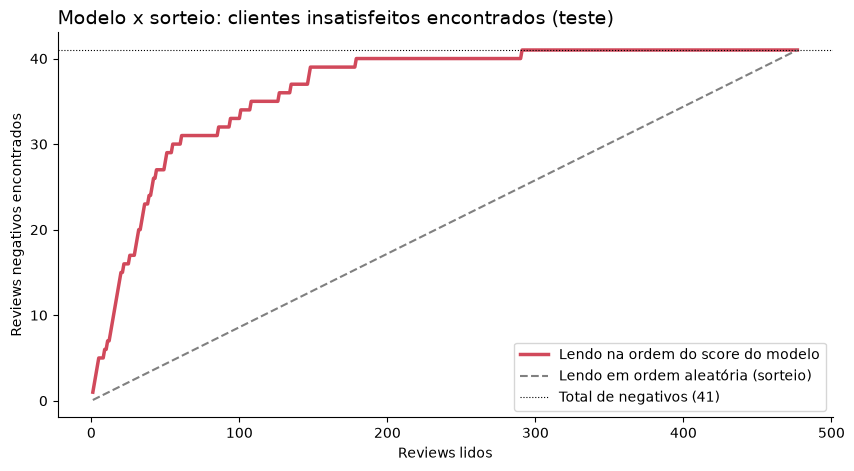

Lendo  25 reviews: modelo encontra 16 negativos | sorteio, 2.1
Lendo  50 reviews: modelo encontra 28 negativos | sorteio, 4.3
Lendo 100 reviews: modelo encontra 33 negativos | sorteio, 8.6


In [65]:
ganho = ganho_vs_sorteio(y_test, prob_teste)

plt.figure(figsize=(10, 5))
plt.plot(ganho['Lidos'], ganho['Modelo'], color='#D1495B', lw=2.5, label='Lendo na ordem do score do modelo')
plt.plot(ganho['Lidos'], ganho['Sorteio'], color='grey', ls='--', label='Lendo em ordem aleatória (sorteio)')
plt.axhline(y_test.sum(), color='black', lw=0.8, ls=':', label=f'Total de negativos ({y_test.sum()})')
plt.xlabel('Reviews lidos')
plt.ylabel('Reviews negativos encontrados')
plt.title('Modelo x sorteio: clientes insatisfeitos encontrados (teste)', fontsize=14, loc='left')
plt.legend()
sns.despine()
salvar('Ganho do modelo x sorteio')
plt.show()

for n in [25, 50, 100]:
    linha = ganho.iloc[n - 1]
    print(f'Lendo {n:>3} reviews: modelo encontra {int(linha["Modelo"])} negativos | sorteio, {linha["Sorteio"]:.1f}')

📌 **Nota**
- 🔎 Lendo os **25 reviews** de maior score, o time encontra **16 negativos**; num sorteio, encontraria **2**. Com **50 reviews**, são **28 contra 4**.
- 🔎 Com **100 reviews** (21% do teste), o modelo encontra **33 dos 41 negativos (80%)**, contra 8,6 de um sorteio.
- 💡 Mesmo sem um limiar fixo, o score permite **priorizar a leitura**: os primeiros reviews da fila concentram a maior parte dos clientes insatisfeitos.

# ✅ RESPOSTA À PERGUNTA DE NEGÓCIO

> *É possível identificar automaticamente os clientes insatisfeitos a partir do que eles escrevem, para que o time de atendimento aja antes que o problema cresça?*

**Sim.** Com o texto do review, o modelo encontra **2 em cada 3 clientes insatisfeitos** (recall de 65,9% no teste), sinalizando só **9,4%** dos reviews para leitura, e com **3 em cada 5 alertas corretos**.

| Pergunta | Resposta | Onde está |
|---|---|---|
| Dá para identificar os insatisfeitos pelo texto? | Sim: PR-AUC de **0,595**, ~7x melhor que um sorteio | Fase 04, item 1 |
| Quanto trabalho o time economiza? | Lendo **45 de 477** reviews, encontra **27 dos 41** negativos (sorteio: ~4) | Fase 03, item 8.3 |
| O que mais indica insatisfação? | **Negações** (*not*, *no*) e intenção de **devolução** (*back*, *return*) | Fase 04, item 3 |
| A variação do produto importa? | Pouco: associação fraca (V = 0,10) e quase nenhum peso no modelo | H4 e Fase 04, item 3 |
| Dá para confiar na probabilidade? | Como **ordem de prioridade**, sim; como chance exata, não (ela superestima o risco) | Fase 03, item 8.4 |

### As hipóteses, revisitadas

| # | Hipótese | Na EDA | No modelo |
|---|---|---|---|
| H3 | Negativos são mais longos | ✅ Efeito moderado (0,36) | O tamanho não entra no modelo; o conteúdo do texto já captura a explicação do problema |
| H4 | Algumas variações têm mais negativos | ✅ Associação fraca (V = 0,10) | Confirmado: a variação quase não pesa (queda de 0,024 na PR-AUC) |
| H5 | Negações aparecem mais nos negativos | ✅ Odds ratio de 6,9 | Confirmado: *not* é a variável mais relevante na seleção e a de maior peso no modelo |
| H6 | Negativos falam de defeitos | ⚠️ Parcial | Confirmado: *stopped*, *back*, *return*, *useless* estão entre as palavras de maior peso |

# 💡 INSIGHTS

1. **Clientes insatisfeitos escrevem mais:** o review negativo mediano tem **o dobro do tamanho** do positivo (efeito moderado). Eles explicam o problema, e isso é informação valiosa para o produto.
2. **"Not" é a palavra mais importante do modelo:** um review com negação tem **7 vezes mais chance** de ser negativo. Remover negações na limpeza (como na versão original) **apaga o principal sinal de insatisfação**.
3. **Intenção de devolução é detectável:** *back* e *return* estão entre as palavras mais ligadas a reviews negativos. Esses clientes devem ter **prioridade no atendimento**.
4. **Modelos simples venceram:** com poucos exemplos e milhares de palavras, a **Regressão Logística** foi mais estável que XGBoost, Random Forest e LightGBM, que decoraram o treino (sobreajuste).
5. **O modelo reduz o trabalho manual:** lendo **~9%** dos reviews, o time encontra **2 em cada 3** clientes insatisfeitos, quase **7 vezes mais** que lendo ao acaso.
6. **O rótulo tem limitações:** reviews nota 3 são considerados positivos, mas muitos contêm críticas. Eles respondem por **39% dos alarmes falsos**.

### Os limites, ditos com todas as letras

- **Poucos negativos:** só 205 reviews negativos na base (41 no teste). Cada review muda o recall em 2,4 pontos percentuais, e as métricas têm margem de erro grande.
- **Rótulo imperfeito:** reviews nota 3 são considerados positivos, mas muitos contêm críticas (7 dos 18 alarmes falsos).
- **Palavras isoladas:** o modelo não entende contexto, ironia ou comparações (*"does not disappoint"*, *"Fire HD does so much more"*).
- **Probabilidade superestimada:** o score serve como ordem de prioridade, não como chance exata.
- **Base específica:** reviews em inglês de produtos Amazon Alexa, de maio a julho de 2018. Para outros produtos ou idiomas, o modelo precisaria ser retreinado.

# 🚀 PRÓXIMOS PASSOS

1. **Rótulo melhor:** revisar os reviews nota 3, hoje rotulados como positivos, e considerar uma classe "neutra".
2. **Mais dados negativos:** só 205 reviews negativos limitam o modelo; coletar mais exemplos é o ganho mais rápido.
3. **Modelos de linguagem:** testar embeddings ou um modelo pré-treinado (ex.: BERT/DistilBERT), que entendem contexto e sarcasmo.
4. **Monitoramento:** acompanhar em produção a precisão dos alertas (quantos o time confirma como negativos) e ajustar o limiar.
5. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que o time de atendimento use o modelo **sem abrir o notebook**, criamos um app simples em **Streamlit**:
1. O usuário escreve (ou cola) um review e escolhe a variação do produto.
2. O app mostra se o review é **positivo ou negativo**, o **score de negatividade** e as **palavras que mais pesaram** na decisão.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz, depois de rodar a Fase 05, que gera `Model/modelo_sentimento.pkl`):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [66]:
%%writefile ../app.py
import pickle
from pathlib import Path

import pandas as pd
import streamlit as st

from src.texto import contribuicao_palavras

st.set_page_config(page_title="Análise de Sentimento 💬", page_icon="💬")
st.title("💬 Análise de Sentimento de Reviews")
st.markdown("Escreva um review **em inglês** de um produto Amazon Alexa e descubra se ele é **positivo** ou **negativo**.")

CAMINHO_MODELO = Path(__file__).parent / "Model" / "modelo_sentimento.pkl"


### Carregamento do modelo
@st.cache_resource
def carregar_modelo(caminho):
    with open(caminho, "rb") as arquivo:
        return pickle.load(arquivo)


if not CAMINHO_MODELO.exists():
    st.error("Modelo não encontrado. Execute o notebook até a Fase 05 para gerar `Model/modelo_sentimento.pkl`.")
    st.stop()

modelo = carregar_modelo(CAMINHO_MODELO)
pipeline, limiar = modelo["pipeline"], modelo["limiar"]

### Entrada do usuário
texto = st.text_area("Review", "It stopped working after two weeks and customer support did not help.", height=120)
variacao = st.selectbox("Variação do produto", modelo["variacoes"])

### Previsão
if st.button("Analisar sentimento", type="primary"):
    if not texto.strip():
        st.warning("Escreva um review para analisar.")
        st.stop()

    dados = pd.DataFrame({"verified_reviews": [texto], "variation": [variacao]})
    prob_negativo = pipeline.predict_proba(dados)[0, 1]

    if prob_negativo >= limiar:
        st.error(f"😞 **Review NEGATIVO** (score de negatividade: {prob_negativo:.0%})")
        st.markdown("➡️ **Ação sugerida:** encaminhar para o time de atendimento entrar em contato com o cliente.")
    else:
        st.success(f"😀 **Review POSITIVO** (score de negatividade: {prob_negativo:.0%})")

    st.caption(f"O review é classificado como negativo quando o score passa de {limiar:.0%} "
               "(limiar escolhido para encontrar a maioria dos clientes insatisfeitos).")

    # Palavras que mais pesaram na decisão
    palavras = contribuicao_palavras(pipeline, dados)
    if not palavras.empty:
        st.markdown("#### Palavras que mais pesaram")
        tabela = pd.DataFrame({
            "Palavra": palavras.index,
            "Empurra para": ["Negativo 😞" if v > 0 else "Positivo 😀" for v in palavras.values],
            "Peso": palavras.values.round(2),
        })
        st.dataframe(tabela, hide_index=True, width="stretch")

Overwriting ../app.py
